In [1]:
!pip install SimpleITK pydicom pandas numpy scikit-image --quiet

## Step 1: Preprocessing pipeline for CT nodule data (LUNA16)
Task = LUNA16 false-positive reduction: label 1 = candidate is a real nodule, 0 = not a nodule (NOT malignancy).
Each candidate becomes a 2.5D patch: axial / coronal / sagittal planes through the candidate centre, stacked as
3 channels (Roth et al. 2014; Setio et al. 2016 used 50 mm patches at 64 px).

In [2]:
import os
import shutil
import numpy as np
import pandas as pd
import SimpleITK as sitk
from pathlib import Path


def find_file(name, search_dir="/kaggle/input"):
   for root, dirs, files in os.walk(search_dir):
       if name in files:
           return os.path.join(root, name)
   return None


# candidates_V2.csv is the version recommended by the LUNA16 organisers; fall back to V1 if the mirror lacks it.
CANDIDATES_CSV = find_file("candidates_V2.csv") or find_file("candidates.csv")
if CANDIDATES_CSV is None:
   raise FileNotFoundError("No candidates(_V2).csv under /kaggle/input. Check that the LUNA16 dataset is attached.")
NODULE_ANNOTATIONS_CSV = find_file("annotations.csv")     # nodule centres + diameters (used for EDA only)
RAW_DATA_DIR = "/kaggle/input"                             # .mhd files may sit outside the CSV folder
print(f"Candidates file: {CANDIDATES_CSV}")


OUTPUT_DIR = "/kaggle/working/preprocessed"
CROP_SIZE = 64             # pixels per side
CROP_MM = 50.0             # physical side length of the patch (Setio et al. 2016)
HU_MIN, HU_MAX = -1000, 400
NEGATIVE_TO_POSITIVE_RATIO = 3
RANDOM_SEED = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

def load_ct_volume(mhd_path):
   """Load a .mhd/.raw CT scan, clip to the lung window and scale to [0, 1].
   Kept as a SimpleITK image so origin, spacing and direction stay attached to the voxels."""
   img = sitk.ReadImage(mhd_path, sitk.sitkFloat32)
   img = sitk.Clamp(img, sitk.sitkFloat32, HU_MIN, HU_MAX)
   return (img - HU_MIN) / (HU_MAX - HU_MIN)

def extract_25d_crop(img, world_xyz, crop_size=CROP_SIZE, crop_mm=CROP_MM):
   """Resample an isotropic cube of crop_mm around the candidate (world mm coordinates) and return its three
   central orthogonal planes (axial, coronal, sagittal) as a (3, crop_size, crop_size) array.
   Resampling to a fixed mm grid removes the scanner-dependent pixel spacing / slice thickness."""
   sp = crop_mm / crop_size
   D = np.array(img.GetDirection()).reshape(3, 3)
   ref = sitk.Image(crop_size, crop_size, crop_size, sitk.sitkFloat32)
   ref.SetSpacing((sp, sp, sp))
   ref.SetDirection(img.GetDirection())
   ref.SetOrigin(tuple(float(v) for v in np.asarray(world_xyz) - D @ np.full(3, sp * (crop_size - 1) / 2.0)))
   # outside the scan -> 0 (= -1000 HU, air)
   cube = sitk.GetArrayFromImage(sitk.Resample(img, ref, sitk.Transform(), sitk.sitkLinear, 0.0))  # z, y, x
   c = crop_size // 2
   return np.stack([cube[c], cube[:, c, :], cube[:, :, c]]).astype(np.float32)


def main():
   annotations = pd.read_csv(CANDIDATES_CSV)
   print(f"Loaded {len(annotations)} total candidates")

   # one path per series (some Kaggle mirrors contain duplicated subset folders)
   mhd_files = {p.stem: p for p in Path(RAW_DATA_DIR).rglob("*.mhd")}
   print(f"Found {len(mhd_files)} CT series")
   annotations = annotations[annotations["seriesuid"].isin(mhd_files)]
   print(annotations["class"].value_counts(), "\n(class balance before subsampling, available scans only)")

   # Balance: keep all positives, subsample negatives
   positives = annotations[annotations["class"] == 1]
   negatives = annotations[annotations["class"] == 0]
   n_negatives_to_keep = min(len(negatives), len(positives) * NEGATIVE_TO_POSITIVE_RATIO)
   negatives_sampled = negatives.sample(n=n_negatives_to_keep, random_state=RANDOM_SEED)
   annotations = pd.concat([positives, negatives_sampled]).sample(frac=1, random_state=RANDOM_SEED)
   print(f"After subsampling: {len(positives)} positive, {len(negatives_sampled)} negative "
         f"({len(annotations)} total candidates to process)")

   records = []
   for series_uid, series_annotations in annotations.groupby("seriesuid"):
       img = load_ct_volume(str(mhd_files[series_uid]))

       for idx, row in series_annotations.iterrows():
           crop = extract_25d_crop(img, (row["coordX"], row["coordY"], row["coordZ"]))

           out_name = f"{series_uid}_{idx}.npy"
           np.save(os.path.join(OUTPUT_DIR, out_name), crop)

           records.append({
               "filename": out_name,
               "series_uid": series_uid,
               "label": int(row["class"]),
           })

   labels_df = pd.DataFrame(records)
   labels_df.to_csv(os.path.join(OUTPUT_DIR, "labels.csv"), index=False)
   if NODULE_ANNOTATIONS_CSV:
       shutil.copy(NODULE_ANNOTATIONS_CSV, os.path.join(OUTPUT_DIR, "nodule_annotations.csv"))
   print(f"Saved {len(labels_df)} preprocessed crops to {OUTPUT_DIR}")
   if len(labels_df) > 0 and "label" in labels_df.columns:
       print(labels_df["label"].value_counts())
   else:
       print("WARNING: no crops were produced. 0 matching CT series means the .mhd files were not found "
             "under /kaggle/input or their names do not match candidates seriesuid.")


if __name__ == "__main__":
   main()

Candidates file: /kaggle/input/datasets/avc0706/luna16/candidates_V2/candidates_V2.csv
Loaded 754975 total candidates
Found 888 CT series
class
0    753418
1      1557
Name: count, dtype: int64 
(class balance before subsampling, available scans only)
After subsampling: 1557 positive, 4671 negative (6228 total candidates to process)
Saved 6228 preprocessed crops to /kaggle/working/preprocessed
label
0    4671
1    1557
Name: count, dtype: int64


## Step 2: Patient-level train/val/test split.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

LABELS_CSV = "/kaggle/working/preprocessed/labels.csv"
OUTPUT_DIR = "/kaggle/working/preprocessed"

RANDOM_SEED = 42
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15


def main():
   df = pd.read_csv(LABELS_CSV)


   unique_patients = df["series_uid"].unique()
   print(f"Total unique patients/series: {len(unique_patients)}")


   train_patients, temp_patients = train_test_split(
       unique_patients, train_size=TRAIN_FRAC, random_state=RANDOM_SEED
   )
   val_size_relative = VAL_FRAC / (1 - TRAIN_FRAC)
   val_patients, test_patients = train_test_split(
       temp_patients, train_size=val_size_relative, random_state=RANDOM_SEED
   )


   df["split"] = "test"
   df.loc[df["series_uid"].isin(train_patients), "split"] = "train"
   df.loc[df["series_uid"].isin(val_patients), "split"] = "val"


   # sanity check: no patient overlap across splits
   train_set = set(df[df["split"] == "train"]["series_uid"])
   val_set = set(df[df["split"] == "val"]["series_uid"])
   test_set = set(df[df["split"] == "test"]["series_uid"])
   assert not (train_set & val_set), "Patient leakage between train/val!"
   assert not (train_set & test_set), "Patient leakage between train/test!"
   assert not (val_set & test_set), "Patient leakage between val/test!"
   print("No patient leakage across splits - confirmed.")


   print(df.groupby("split")["label"].agg(crops="count", positives="sum"))
   df.to_csv(f"{OUTPUT_DIR}/labels_split.csv", index=False)
   print(f"Saved split file to {OUTPUT_DIR}/labels_split.csv")



if __name__ == "__main__":
   main()

Total unique patients/series: 876
No patient leakage across splits - confirmed.
       crops  positives
split                  
test    1039        260
train   4263       1072
val      926        225
Saved split file to /kaggle/working/preprocessed/labels_split.csv


## Step 3: Exploratory Data Analysis

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "/kaggle/working/preprocessed"
LABELS_CSV = f"{DATA_DIR}/labels_split.csv"
FIG_DIR = "/kaggle/working/figures/eda"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_style("whitegrid")


def main():
   df = pd.read_csv(LABELS_CSV)
   print(f"Total crops: {len(df)}")
   print(f"Unique patients/series: {df['series_uid'].nunique()}")
   print(df.groupby("split")["series_uid"].nunique(), "\n(patients per split)")


   # 1. Class balance overall and per split
   fig, axes = plt.subplots(1, 2, figsize=(12, 4))
   df["label"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
   axes[0].set_title("Overall class balance")
   axes[0].set_xlabel("Label (0=non-nodule candidate, 1=nodule)")
   axes[0].set_ylabel("Count")


   split_counts = df.groupby(["split", "label"]).size().unstack(fill_value=0)
   split_counts.plot(kind="bar", stacked=True, ax=axes[1])
   axes[1].set_title("Class balance per split")
   axes[1].set_xlabel("Split")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/class_balance.png", dpi=150)
   plt.close()


   # 2. Nodule diameter distribution (from annotations.csv; candidates have no diameter)
   nodules_csv = f"{DATA_DIR}/nodule_annotations.csv"
   if os.path.exists(nodules_csv):
       nodules = pd.read_csv(nodules_csv)
       nodules = nodules[nodules["seriesuid"].isin(df["series_uid"])]
       plt.figure(figsize=(7, 4))
       sns.histplot(nodules["diameter_mm"], bins=30, kde=True, color="#4C72B0")
       plt.title("Nodule diameter distribution (mm)")
       plt.xlabel("Diameter (mm)")
       plt.tight_layout()
       plt.savefig(f"{FIG_DIR}/diameter_distribution.png", dpi=150)
       plt.close()


   # 3. Sample crop grid (mix of both classes; axial channel shown)
   fig, axes = plt.subplots(2, 5, figsize=(15, 6))
   for label_val, row_idx in [(0, 0), (1, 1)]:
       subset = df[df["label"] == label_val].sample(min(5, (df["label"] == label_val).sum()), random_state=42)
       for col_idx, (_, row) in enumerate(subset.iterrows()):
           crop = np.load(os.path.join(DATA_DIR, row["filename"]))
           axes[row_idx, col_idx].imshow(crop[0], cmap="gray", vmin=0, vmax=1)
           axes[row_idx, col_idx].set_title(f"label={label_val}", fontsize=9)
           axes[row_idx, col_idx].axis("off")
   plt.suptitle("Sample nodule crops by class")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/sample_crops.png", dpi=150)
   plt.close()


   # 3b. One nodule shown as the three input channels (illustrates the 2.5D representation)
   crop = np.load(os.path.join(DATA_DIR, df[df["label"] == 1].sample(1, random_state=42)["filename"].iloc[0]))
   fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
   for ax, view, title in zip(axes, crop, ["Axial (ch 0)", "Coronal (ch 1)", "Sagittal (ch 2)"]):
       ax.imshow(view, cmap="gray", vmin=0, vmax=1)
       ax.set_title(title, fontsize=10)
       ax.axis("off")
   plt.suptitle("2.5D input: three orthogonal 50 mm views of one nodule")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/views_example.png", dpi=150)
   plt.close()


   # 4. Pixel intensity histogram (sanity check on normalization)
   sample_files = df["filename"].sample(min(200, len(df)), random_state=42)
   all_pixels = np.concatenate([
       np.load(os.path.join(DATA_DIR, f)).ravel() for f in sample_files
   ])
   plt.figure(figsize=(7, 4))
   sns.histplot(all_pixels, bins=50, color="#55A868")
   plt.title("Pixel intensity distribution (post lung-window normalization)")
   plt.xlabel("Normalized intensity [0,1]")
   plt.tight_layout()
   plt.savefig(f"{FIG_DIR}/pixel_intensity_hist.png", dpi=150)
   plt.close()

   print(f"\nAll EDA figures saved to {FIG_DIR}")


if __name__ == "__main__":
   main()

Total crops: 6228
Unique patients/series: 876
split
test     132
train    613
val      131
Name: series_uid, dtype: int64 
(patients per split)

All EDA figures saved to /kaggle/working/figures/eda


In [11]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (
   accuracy_score, precision_score, recall_score, f1_score,
   roc_auc_score, average_precision_score, confusion_matrix,
   roc_curve, precision_recall_curve, brier_score_loss,
)
from sklearn.calibration import calibration_curve


sns.set_style("whitegrid")

DATA_DIR = "/kaggle/working/preprocessed"
LABELS_CSV = f"{DATA_DIR}/labels_split.csv"
OUT_DIR = "/kaggle/working/model_results"
FIG_DIR = "/kaggle/working/figures/per_model"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)


BATCH_SIZE = 32
NUM_EPOCHS = 25
LEARNING_RATE = 1e-4
INPUT_SIZE = 224            # ImageNet backbones are built for 224 px; 64 px leaves only a 2x2 final feature map
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)


# applied to every split, after augmentation: upsample + ImageNet normalisation (matches pretraining)
to_model_input = transforms.Compose([
   transforms.Resize((INPUT_SIZE, INPUT_SIZE), antialias=True),
   transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def expected_calibration_error(y, p, n_bins=10):
   """ECE (Guo et al. 2017): bin-size-weighted gap between mean confidence and observed positive rate."""
   y, p = np.asarray(y), np.asarray(p)
   bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
   return float(sum(abs(y[bins == b].mean() - p[bins == b].mean()) * (bins == b).mean()
                    for b in range(n_bins) if (bins == b).any()))


class NoduleDataset(Dataset):
   def __init__(self, df, data_dir, transform=None):
       self.df = df.reset_index(drop=True)
       self.data_dir = data_dir
       self.transform = transform


   def __len__(self):
       return len(self.df)

   def __getitem__(self, idx):
       row = self.df.iloc[idx]
       crop = np.load(os.path.join(self.data_dir, row["filename"]))   # (3, H, W): axial, coronal, sagittal
       crop_tensor = torch.from_numpy(crop).float()
       if self.transform:
           crop_tensor = self.transform(crop_tensor)
       return crop_tensor, int(row["label"]), row["filename"]


def build_model(name):
   if name == "resnet50":
       m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
       m.fc = nn.Linear(m.fc.in_features, 2)
   elif name == "densenet121":
       m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
       m.classifier = nn.Linear(m.classifier.in_features, 2)
   elif name == "efficientnet_b0":
       m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
       m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
   elif name == "vgg16_bn":
       m = models.vgg16_bn(weights=models.VGG16_BN_Weights.IMAGENET1K_V1)
       m.classifier[6] = nn.Linear(m.classifier[6].in_features, 2)
   else:
       raise ValueError(f"Unknown model name: {name}")
   return m.to(DEVICE)


# Train / eval loops
def train_one_epoch(model, loader, optimizer, criterion):
   model.train()
   running_loss, correct, total = 0.0, 0, 0
   for images, labels, _ in loader:
       images, labels = images.to(DEVICE), labels.to(DEVICE)
       optimizer.zero_grad()
       outputs = model(images)
       loss = criterion(outputs, labels)
       loss.backward()
       optimizer.step()
       running_loss += loss.item() * images.size(0)
       correct += (outputs.argmax(1) == labels).sum().item()
       total += images.size(0)
   return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, return_predictions=False):
   model.eval()
   all_labels, all_preds, all_probs, all_files = [], [], [], []
   running_loss, criterion = 0.0, nn.CrossEntropyLoss()


   for images, labels, filenames in loader:
       images_dev, labels_dev = images.to(DEVICE), labels.to(DEVICE)
       outputs = model(images_dev)
       loss = criterion(outputs, labels_dev)
       running_loss += loss.item() * images.size(0)


       probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
       preds = outputs.argmax(dim=1).cpu().numpy()


       all_labels.extend(labels.numpy())
       all_preds.extend(preds)
       all_probs.extend(probs)
       all_files.extend(filenames)


   metrics = {
       "loss": running_loss / len(loader.dataset),
       "accuracy": accuracy_score(all_labels, all_preds),
       "precision": precision_score(all_labels, all_preds, zero_division=0),
       "recall_sensitivity": recall_score(all_labels, all_preds, zero_division=0),
       "f1": f1_score(all_labels, all_preds, zero_division=0),
       "roc_auc": roc_auc_score(all_labels, all_probs) if len(set(all_labels)) > 1 else float("nan"),
       "pr_auc": average_precision_score(all_labels, all_probs),
       "brier": brier_score_loss(all_labels, all_probs),
       "ece": expected_calibration_error(all_labels, all_probs),
   }
   tn, fp, fn, tp = confusion_matrix(all_labels, all_preds, labels=[0, 1]).ravel()
   metrics["specificity"] = tn / (tn + fp) if (tn + fp) > 0 else 0.0


   if return_predictions:
       pred_df = pd.DataFrame({
           "filename": all_files, "label": all_labels,
           "pred": all_preds, "prob": all_probs,
       })
       return metrics, pred_df
   return metrics


# Full train-one-model
def train_model(model_name, train_loader, val_loader, test_loader, num_epochs=NUM_EPOCHS):
   print(f"\n{'='*60}\nTraining {model_name} ({num_epochs} epochs)\n{'='*60}")
   model = build_model(model_name)
   criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)   # 1:3 imbalance -> keep sensitivity at threshold 0.5
   optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
   scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=3)


   history = []
   best_val_auc = 0.0
   checkpoint_path = f"{OUT_DIR}/{model_name}_best.pt"


   for epoch in range(num_epochs):
       start = time.time()
       train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
       val_metrics = evaluate(model, val_loader)
       scheduler.step(val_metrics["roc_auc"])
       elapsed = time.time() - start


       history.append({
           "epoch": epoch + 1, "train_loss": train_loss, "train_acc": train_acc,
           "val_loss": val_metrics["loss"], "val_acc": val_metrics["accuracy"],
           "val_roc_auc": val_metrics["roc_auc"], "val_pr_auc": val_metrics["pr_auc"],
           "val_sensitivity": val_metrics["recall_sensitivity"], "val_specificity": val_metrics["specificity"],
       })
       print(f"[{model_name}] epoch {epoch+1}/{num_epochs} "
             f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
             f"val_acc={val_metrics['accuracy']:.4f} val_auc={val_metrics['roc_auc']:.4f} ({elapsed:.1f}s)")


       if val_metrics["roc_auc"] > best_val_auc:
           best_val_auc = val_metrics["roc_auc"]
           torch.save(model.state_dict(), checkpoint_path)


   history_df = pd.DataFrame(history)
   history_df.to_csv(f"{OUT_DIR}/{model_name}_history.csv", index=False)


   model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
   test_metrics, test_pred_df = evaluate(model, test_loader, return_predictions=True)
   test_pred_df.to_csv(f"{OUT_DIR}/{model_name}_test_predictions.csv", index=False)
   pd.DataFrame([test_metrics]).to_csv(f"{OUT_DIR}/{model_name}_test_metrics.csv", index=False)


   print(f"\n[{model_name}] FINAL TEST METRICS:")
   for k, v in test_metrics.items():
       print(f"  {k}: {v:.4f}")

   return model, history_df, test_metrics, test_pred_df


# Per-model plotting: train vs val curves, ROC, PR, confusion matrix
def plot_model_report(model_name, history_df, test_metrics, test_pred_df):
   fig, axes = plt.subplots(2, 3, figsize=(16, 9))

   # 1. Train vs Val loss
   axes[0, 0].plot(history_df["epoch"], history_df["train_loss"], label="train")
   axes[0, 0].plot(history_df["epoch"], history_df["val_loss"], label="val")
   axes[0, 0].set_title(f"{model_name} - Loss")
   axes[0, 0].set_xlabel("Epoch")
   axes[0, 0].legend()

   # 2. Train vs Val accuracy
   axes[0, 1].plot(history_df["epoch"], history_df["train_acc"], label="train")
   axes[0, 1].plot(history_df["epoch"], history_df["val_acc"], label="val")
   axes[0, 1].set_title(f"{model_name} - Accuracy")
   axes[0, 1].set_xlabel("Epoch")
   axes[0, 1].legend()

   # 3. Val ROC-AUC / PR-AUC across epochs
   axes[0, 2].plot(history_df["epoch"], history_df["val_roc_auc"], label="val ROC-AUC")
   axes[0, 2].plot(history_df["epoch"], history_df["val_pr_auc"], label="val PR-AUC")
   axes[0, 2].set_title(f"{model_name} - Val ROC-AUC / PR-AUC")
   axes[0, 2].set_xlabel("Epoch")
   axes[0, 2].legend()

   # 4. ROC curve (final test set)
   fpr, tpr, _ = roc_curve(test_pred_df["label"], test_pred_df["prob"])
   axes[1, 0].plot(fpr, tpr, label=f"AUC={test_metrics['roc_auc']:.3f}")
   axes[1, 0].plot([0, 1], [0, 1], "k:", alpha=0.5)
   axes[1, 0].set_title(f"{model_name} - ROC curve (test)")
   axes[1, 0].set_xlabel("False Positive Rate")
   axes[1, 0].set_ylabel("True Positive Rate")
   axes[1, 0].legend()

   # 5. Precision-Recall curve (final test set)
   precision, recall, _ = precision_recall_curve(test_pred_df["label"], test_pred_df["prob"])
   axes[1, 1].plot(recall, precision, label=f"AP={test_metrics['pr_auc']:.3f}")
   axes[1, 1].set_title(f"{model_name} - PR curve (test)")
   axes[1, 1].set_xlabel("Recall")
   axes[1, 1].set_ylabel("Precision")
   axes[1, 1].legend()

   # 6. Confusion matrix (final test set)
   cm = confusion_matrix(test_pred_df["label"], test_pred_df["pred"])
   sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1, 2], cbar=False)
   axes[1, 2].set_title(f"{model_name} - Confusion Matrix (test)")
   axes[1, 2].set_xlabel("Predicted")
   axes[1, 2].set_ylabel("Actual")

   plt.tight_layout()
   save_path = f"{FIG_DIR}/{model_name}_full_report.png"
   plt.savefig(save_path, dpi=150)
   plt.show()
   print(f"Saved {save_path}")

   # Print a clean metrics table too
   metrics_table = pd.DataFrame([test_metrics]).T.rename(columns={0: model_name})
   print(f"\n{model_name} test metrics:")
   print(metrics_table.round(4))


df = pd.read_csv(LABELS_CSV)
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
test_df = df[df["split"] == "test"]
print(f"train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")


n_pos = int(train_df["label"].sum())
n_neg = len(train_df) - n_pos
CLASS_WEIGHTS = torch.tensor([len(train_df) / (2 * n_neg), len(train_df) / (2 * n_pos)],
                            dtype=torch.float32, device=DEVICE)
print(f"Class weights (neg, pos): {CLASS_WEIGHTS.tolist()}")


train_transform = transforms.Compose([
   transforms.RandomHorizontalFlip(p=0.5),
   transforms.RandomVerticalFlip(p=0.5),
   transforms.RandomRotation(degrees=15),   # empty corners filled with 0 = air
   to_model_input,
])


train_loader = DataLoader(NoduleDataset(train_df, DATA_DIR, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(NoduleDataset(val_df, DATA_DIR, to_model_input),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(NoduleDataset(test_df, DATA_DIR, to_model_input),
                         batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


print("Setup complete. Loaders ready. Proceed to the per-model training blocks.")

Using device: cuda
train=4263, val=926, test=1039
Class weights (neg, pos): [0.6679724454879761, 1.9883395433425903]
Setup complete. Loaders ready. Proceed to the per-model training blocks.


## Train ResNet50


Training resnet50 (25 epochs)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 181MB/s] 


[resnet50] epoch 1/25 train_loss=0.6782 train_acc=0.5970 val_acc=0.7365 val_auc=0.5222 (47.7s)
[resnet50] epoch 2/25 train_loss=0.6651 train_acc=0.6331 val_acc=0.6058 val_auc=0.6174 (46.2s)
[resnet50] epoch 3/25 train_loss=0.6482 train_acc=0.6137 val_acc=0.6015 val_auc=0.5319 (45.6s)
[resnet50] epoch 4/25 train_loss=0.6371 train_acc=0.6355 val_acc=0.5821 val_auc=0.6154 (45.9s)
[resnet50] epoch 5/25 train_loss=0.6227 train_acc=0.6183 val_acc=0.6458 val_auc=0.6252 (45.7s)
[resnet50] epoch 6/25 train_loss=0.6065 train_acc=0.6662 val_acc=0.6674 val_auc=0.6356 (45.6s)
[resnet50] epoch 7/25 train_loss=0.6054 train_acc=0.6486 val_acc=0.6965 val_auc=0.6232 (45.8s)
[resnet50] epoch 8/25 train_loss=0.5977 train_acc=0.6547 val_acc=0.5572 val_auc=0.6001 (45.6s)
[resnet50] epoch 9/25 train_loss=0.5868 train_acc=0.6594 val_acc=0.6080 val_auc=0.5788 (45.5s)
[resnet50] epoch 10/25 train_loss=0.5838 train_acc=0.6721 val_acc=0.5410 val_auc=0.6463 (45.8s)
[resnet50] epoch 11/25 train_loss=0.5861 train_ac

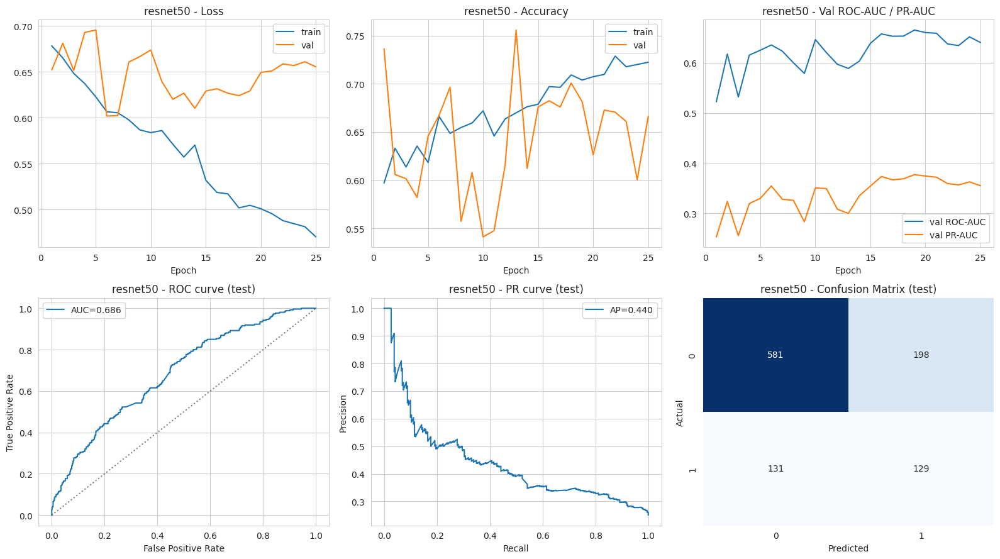

Saved /kaggle/working/figures/per_model/resnet50_full_report.png

resnet50 test metrics:
                    resnet50
loss                  0.6142
accuracy              0.6833
precision             0.3945
recall_sensitivity    0.4962
f1                    0.4395
roc_auc               0.6860
pr_auc                0.4401
brier                 0.2095
ece                   0.1755
specificity           0.7458


In [12]:
resnet50_model, resnet50_history, resnet50_test_metrics, resnet50_test_preds = train_model(
   "resnet50", train_loader, val_loader, test_loader
)

plot_model_report("resnet50", resnet50_history, resnet50_test_metrics, resnet50_test_preds)

## Train DenseNet121


Training densenet121 (25 epochs)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 174MB/s] 


[densenet121] epoch 1/25 train_loss=0.6978 train_acc=0.5599 val_acc=0.7527 val_auc=0.6025 (46.5s)
[densenet121] epoch 2/25 train_loss=0.6757 train_acc=0.5822 val_acc=0.7419 val_auc=0.5239 (46.0s)
[densenet121] epoch 3/25 train_loss=0.6577 train_acc=0.5961 val_acc=0.7484 val_auc=0.6774 (46.1s)
[densenet121] epoch 4/25 train_loss=0.6404 train_acc=0.6183 val_acc=0.7495 val_auc=0.6122 (46.2s)
[densenet121] epoch 5/25 train_loss=0.6253 train_acc=0.6144 val_acc=0.6987 val_auc=0.6326 (46.1s)
[densenet121] epoch 6/25 train_loss=0.6239 train_acc=0.6244 val_acc=0.5086 val_auc=0.6670 (46.1s)
[densenet121] epoch 7/25 train_loss=0.6142 train_acc=0.6343 val_acc=0.6598 val_auc=0.6489 (46.1s)
[densenet121] epoch 8/25 train_loss=0.5830 train_acc=0.6812 val_acc=0.6555 val_auc=0.6738 (46.1s)
[densenet121] epoch 9/25 train_loss=0.5686 train_acc=0.6730 val_acc=0.6641 val_auc=0.6859 (46.2s)
[densenet121] epoch 10/25 train_loss=0.5639 train_acc=0.6578 val_acc=0.6641 val_auc=0.6575 (46.2s)
[densenet121] epoch

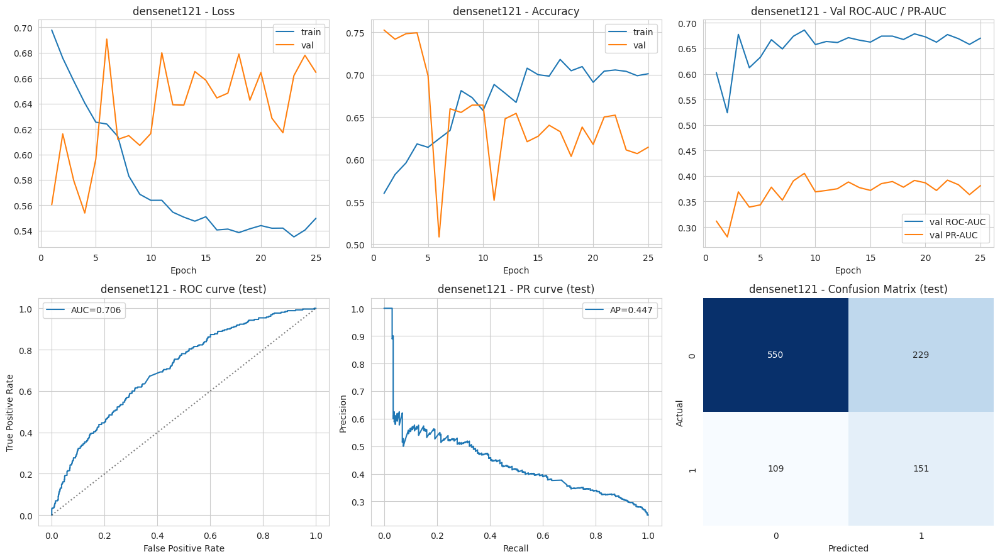

Saved /kaggle/working/figures/per_model/densenet121_full_report.png

densenet121 test metrics:
                    densenet121
loss                     0.5960
accuracy                 0.6747
precision                0.3974
recall_sensitivity       0.5808
f1                       0.4719
roc_auc                  0.7062
pr_auc                   0.4469
brier                    0.2062
ece                      0.1728
specificity              0.7060


In [13]:
densenet121_model, densenet121_history, densenet121_test_metrics, densenet121_test_preds = train_model(
   "densenet121", train_loader, val_loader, test_loader
)

plot_model_report("densenet121", densenet121_history, densenet121_test_metrics, densenet121_test_preds)

## Train EfficientNet-B0


Training efficientnet_b0 (25 epochs)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s] 


[efficientnet_b0] epoch 1/25 train_loss=0.6835 train_acc=0.5644 val_acc=0.7549 val_auc=0.6373 (23.5s)
[efficientnet_b0] epoch 2/25 train_loss=0.6574 train_acc=0.6179 val_acc=0.4741 val_auc=0.6220 (23.1s)
[efficientnet_b0] epoch 3/25 train_loss=0.6430 train_acc=0.6334 val_acc=0.6069 val_auc=0.6283 (23.0s)
[efficientnet_b0] epoch 4/25 train_loss=0.6250 train_acc=0.6404 val_acc=0.3801 val_auc=0.6177 (23.0s)
[efficientnet_b0] epoch 5/25 train_loss=0.6157 train_acc=0.6186 val_acc=0.3790 val_auc=0.5944 (23.1s)
[efficientnet_b0] epoch 6/25 train_loss=0.5964 train_acc=0.6385 val_acc=0.3315 val_auc=0.6011 (23.1s)
[efficientnet_b0] epoch 7/25 train_loss=0.5853 train_acc=0.6348 val_acc=0.4514 val_auc=0.6482 (23.1s)
[efficientnet_b0] epoch 8/25 train_loss=0.5855 train_acc=0.6491 val_acc=0.3855 val_auc=0.6055 (23.2s)
[efficientnet_b0] epoch 9/25 train_loss=0.5896 train_acc=0.6493 val_acc=0.5076 val_auc=0.6724 (23.1s)
[efficientnet_b0] epoch 10/25 train_loss=0.5816 train_acc=0.6446 val_acc=0.3542 va

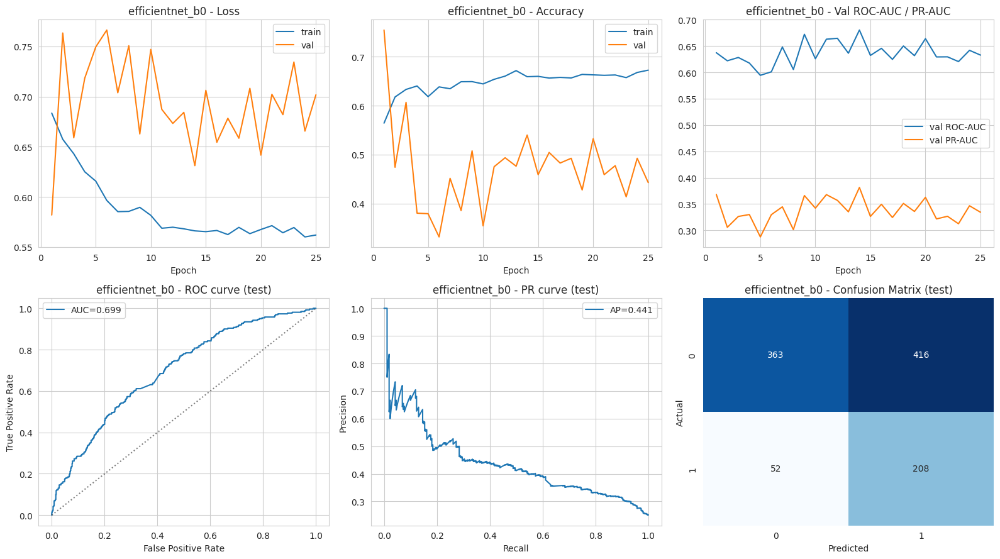

Saved /kaggle/working/figures/per_model/efficientnet_b0_full_report.png

efficientnet_b0 test metrics:
                    efficientnet_b0
loss                         0.6314
accuracy                     0.5496
precision                    0.3333
recall_sensitivity           0.8000
f1                           0.4706
roc_auc                      0.6987
pr_auc                       0.4412
brier                        0.2230
ece                          0.2223
specificity                  0.4660


In [14]:
efficientnet_b0_model, efficientnet_b0_history, efficientnet_b0_test_metrics, efficientnet_b0_test_preds = train_model(
   "efficientnet_b0", train_loader, val_loader, test_loader
)

plot_model_report("efficientnet_b0", efficientnet_b0_history, efficientnet_b0_test_metrics, efficientnet_b0_test_preds)

## Train VGG16-BN


Training vgg16_bn (25 epochs)
Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:02<00:00, 191MB/s]  


[vgg16_bn] epoch 1/25 train_loss=0.7054 train_acc=0.5703 val_acc=0.2667 val_auc=0.5987 (77.6s)
[vgg16_bn] epoch 2/25 train_loss=0.6919 train_acc=0.5369 val_acc=0.3013 val_auc=0.6227 (77.7s)
[vgg16_bn] epoch 3/25 train_loss=0.6919 train_acc=0.5257 val_acc=0.7570 val_auc=0.5407 (77.7s)
[vgg16_bn] epoch 4/25 train_loss=0.6801 train_acc=0.5581 val_acc=0.6577 val_auc=0.6251 (77.6s)
[vgg16_bn] epoch 5/25 train_loss=0.6735 train_acc=0.6017 val_acc=0.6544 val_auc=0.6181 (77.8s)
[vgg16_bn] epoch 6/25 train_loss=0.6586 train_acc=0.6108 val_acc=0.3337 val_auc=0.5740 (77.7s)
[vgg16_bn] epoch 7/25 train_loss=0.6568 train_acc=0.6233 val_acc=0.6134 val_auc=0.6299 (77.9s)
[vgg16_bn] epoch 8/25 train_loss=0.6464 train_acc=0.6080 val_acc=0.5464 val_auc=0.6071 (77.9s)
[vgg16_bn] epoch 9/25 train_loss=0.6401 train_acc=0.6151 val_acc=0.6134 val_auc=0.6477 (78.1s)
[vgg16_bn] epoch 10/25 train_loss=0.6399 train_acc=0.6047 val_acc=0.6749 val_auc=0.6489 (78.0s)
[vgg16_bn] epoch 11/25 train_loss=0.6218 train_ac

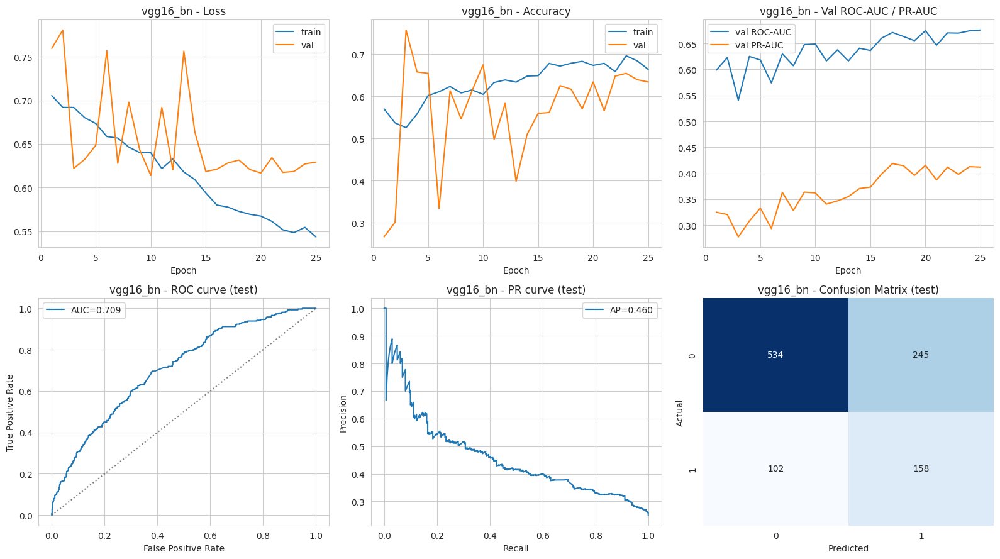

Saved /kaggle/working/figures/per_model/vgg16_bn_full_report.png

vgg16_bn test metrics:
                    vgg16_bn
loss                  0.6228
accuracy              0.6660
precision             0.3921
recall_sensitivity    0.6077
f1                    0.4766
roc_auc               0.7085
pr_auc                0.4602
brier                 0.2149
ece                   0.1973
specificity           0.6855


In [15]:
vgg16_bn_model, vgg16_bn_history, vgg16_bn_test_metrics, vgg16_bn_test_preds = train_model(
   "vgg16_bn", train_loader, val_loader, test_loader
)

plot_model_report("vgg16_bn", vgg16_bn_history, vgg16_bn_test_metrics, vgg16_bn_test_preds)

## Cross-model comparison + voting ensemble

Found trained results for: ['resnet50', 'densenet121', 'efficientnet_b0', 'vgg16_bn']


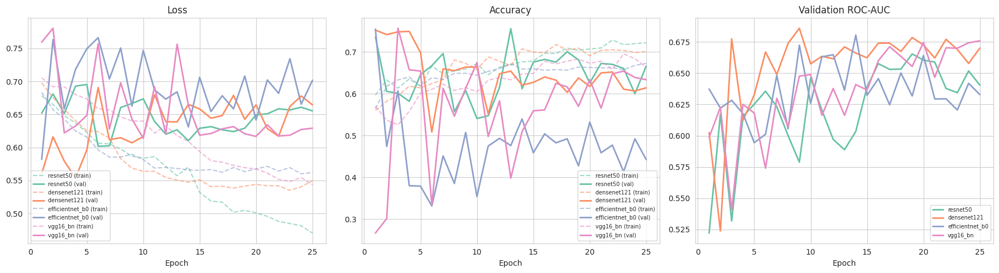


=== Final metrics: individual models + ensembles ===
                 accuracy  precision  recall_sensitivity  specificity      f1  \
resnet50           0.6833     0.3945              0.4962       0.7458  0.4395   
densenet121        0.6747     0.3974              0.5808       0.7060  0.4719   
efficientnet_b0    0.5496     0.3333              0.8000       0.4660  0.4706   
vgg16_bn           0.6660     0.3921              0.6077       0.6855  0.4766   
hard_vote          0.6487     0.3804              0.6423       0.6508  0.4778   
soft_vote          0.6968     0.4259              0.6077       0.7266  0.5008   

                 roc_auc  pr_auc   brier     ece  
resnet50          0.6860  0.4401  0.2095  0.1755  
densenet121       0.7062  0.4469  0.2062  0.1728  
efficientnet_b0   0.6987  0.4412  0.2230  0.2223  
vgg16_bn          0.7085  0.4602  0.2149  0.1973  
hard_vote         0.6948  0.3911  0.2579  0.2267  
soft_vote         0.7198  0.4841  0.2021  0.1794  


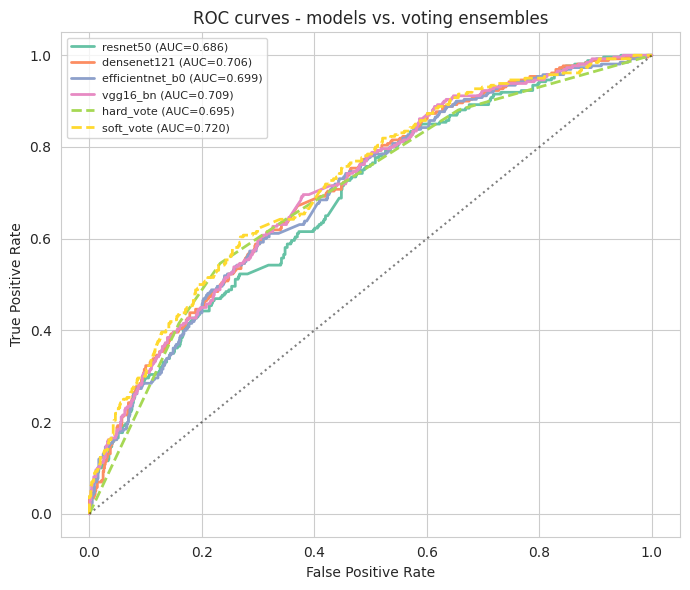

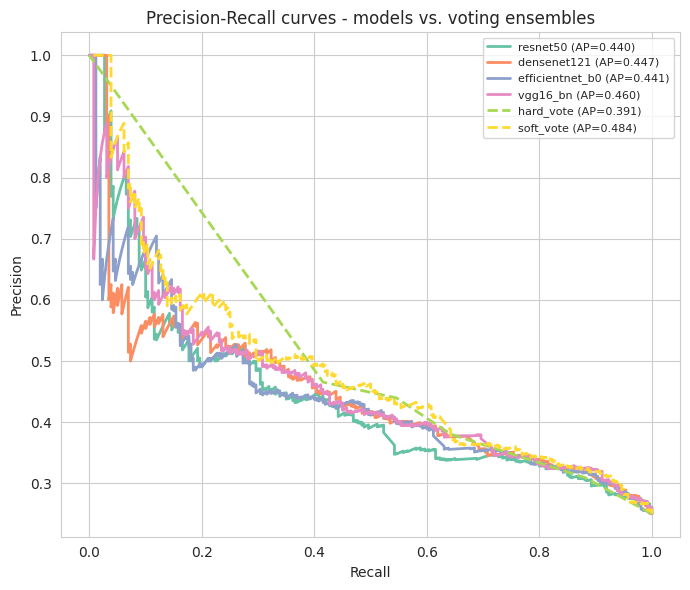

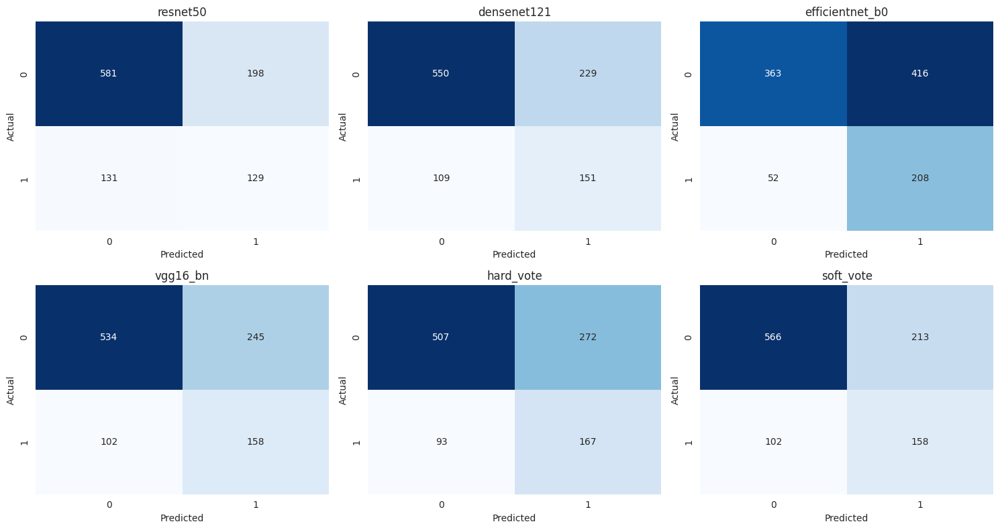

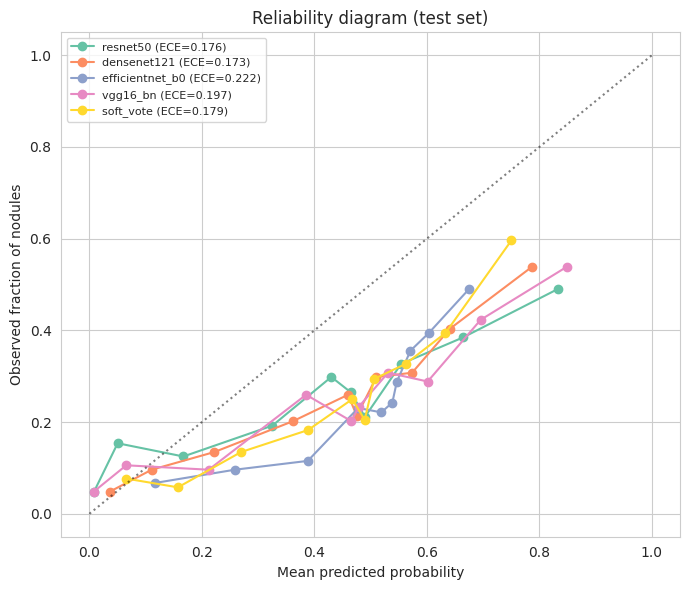

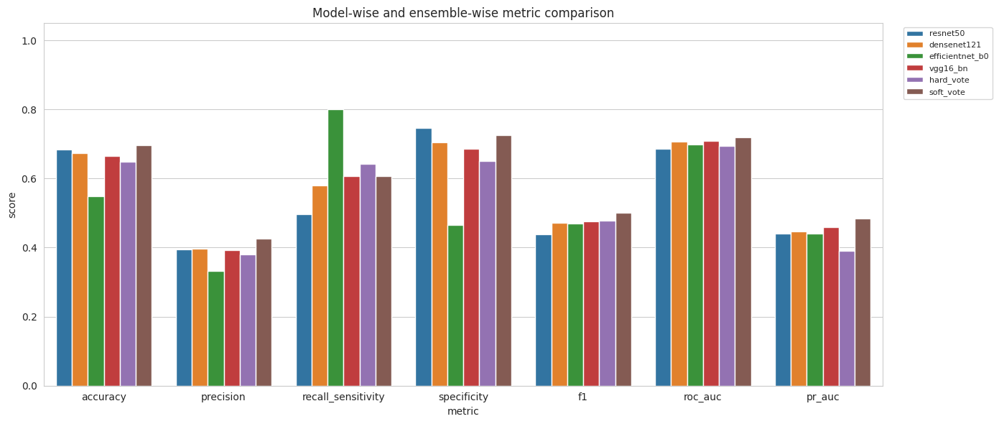


All comparison figures saved to /kaggle/working/figures/comparison


In [16]:
import glob

ALL_POSSIBLE_MODELS = ["resnet50", "densenet121", "efficientnet_b0", "vgg16_bn"]

# Detect which models actually have saved results
trained_models = [
   name for name in ALL_POSSIBLE_MODELS
   if os.path.exists(f"{OUT_DIR}/{name}_history.csv")
   and os.path.exists(f"{OUT_DIR}/{name}_test_predictions.csv")
]
print(f"Found trained results for: {trained_models}")

if len(trained_models) < 2:
   print("Need at least 2 trained models to compare/ensemble. Run more of Blocks 2-5 first.")
else:
   COMPARE_FIG_DIR = "/kaggle/working/figures/comparison"
   os.makedirs(COMPARE_FIG_DIR, exist_ok=True)
   palette = sns.color_palette("Set2", len(trained_models) + 2)

   # -----------------------------------------------------------------
   # 1. Overlaid training curves (loss / accuracy / val ROC-AUC)
   # -----------------------------------------------------------------
   histories = {name: pd.read_csv(f"{OUT_DIR}/{name}_history.csv") for name in trained_models}

   fig, axes = plt.subplots(1, 3, figsize=(18, 5))
   plot_specs = [("train_loss", "val_loss", "Loss"), ("train_acc", "val_acc", "Accuracy"),
                 (None, "val_roc_auc", "Validation ROC-AUC")]
   for ax, (train_col, val_col, title) in zip(axes, plot_specs):
       for i, (name, hist) in enumerate(histories.items()):
           if train_col:
               ax.plot(hist["epoch"], hist[train_col], "--", color=palette[i], alpha=0.6, label=f"{name} (train)")
           ax.plot(hist["epoch"], hist[val_col], "-", color=palette[i], linewidth=2,
                    label=f"{name} (val)" if train_col else name)
       ax.set_title(title)
       ax.set_xlabel("Epoch")
       ax.legend(fontsize=7)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/training_curves_all_models.png", dpi=150)
   plt.show()

   # -----------------------------------------------------------------
   # 2. Load predictions, build hard/soft voting ensembles
   # -----------------------------------------------------------------
   preds = {name: pd.read_csv(f"{OUT_DIR}/{name}_test_predictions.csv").set_index("filename")
             for name in trained_models}


   base = preds[trained_models[0]][["label"]].copy()
   for name in trained_models:
       base[f"{name}_prob"] = preds[name]["prob"]
       base[f"{name}_pred"] = preds[name]["pred"]

   pred_cols = [f"{name}_pred" for name in trained_models]
   base["hard_vote_prob"] = base[pred_cols].mean(axis=1)
   base["hard_vote_pred"] = (base["hard_vote_prob"] >= 0.5).astype(int)   # 2-2 tie -> positive (favours sensitivity)

   prob_cols = [f"{name}_prob" for name in trained_models]
   base["soft_vote_prob"] = base[prob_cols].mean(axis=1)
   base["soft_vote_pred"] = (base["soft_vote_prob"] >= 0.5).astype(int)

   base.to_csv(f"{OUT_DIR}/ensemble_predictions.csv")
   all_variants = trained_models + ["hard_vote", "soft_vote"]

   # -----------------------------------------------------------------
   # 3. Metrics table for all models + both ensembles
   # -----------------------------------------------------------------
   results = {}
   for name in all_variants:
       y_true, y_pred, y_prob = base["label"], base[f"{name}_pred"], base[f"{name}_prob"]
       tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
       results[name] = {
           "accuracy": accuracy_score(y_true, y_pred),
           "precision": precision_score(y_true, y_pred, zero_division=0),
           "recall_sensitivity": recall_score(y_true, y_pred, zero_division=0),
           "specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
           "f1": f1_score(y_true, y_pred, zero_division=0),
           "roc_auc": roc_auc_score(y_true, y_prob),
           "pr_auc": average_precision_score(y_true, y_prob),
           "brier": brier_score_loss(y_true, y_prob),
           "ece": expected_calibration_error(y_true, y_prob),
       }
   metrics_df = pd.DataFrame(results).T
   metrics_df.to_csv(f"{OUT_DIR}/final_metrics_all_models_and_ensembles.csv")
   print("\n=== Final metrics: individual models + ensembles ===")
   print(metrics_df.round(4))

   # -----------------------------------------------------------------
   # 4. Overlaid ROC curves
   # -----------------------------------------------------------------
   plt.figure(figsize=(7, 6))
   for i, name in enumerate(all_variants):
       fpr, tpr, _ = roc_curve(base["label"], base[f"{name}_prob"])
       auc_val = roc_auc_score(base["label"], base[f"{name}_prob"])
       style = "--" if "vote" in name else "-"
       plt.plot(fpr, tpr, style, color=palette[i], linewidth=2, label=f"{name} (AUC={auc_val:.3f})")
   plt.plot([0, 1], [0, 1], "k:", alpha=0.5)
   plt.xlabel("False Positive Rate")
   plt.ylabel("True Positive Rate")
   plt.title("ROC curves - models vs. voting ensembles")
   plt.legend(fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/roc_curves_comparison.png", dpi=150)
   plt.show()

   # -----------------------------------------------------------------
   # 5. Overlaid PR curves
   # -----------------------------------------------------------------
   plt.figure(figsize=(7, 6))
   for i, name in enumerate(all_variants):
       precision, recall, _ = precision_recall_curve(base["label"], base[f"{name}_prob"])
       ap = average_precision_score(base["label"], base[f"{name}_prob"])
       style = "--" if "vote" in name else "-"
       plt.plot(recall, precision, style, color=palette[i], linewidth=2, label=f"{name} (AP={ap:.3f})")
   plt.xlabel("Recall")
   plt.ylabel("Precision")
   plt.title("Precision-Recall curves - models vs. voting ensembles")
   plt.legend(fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/pr_curves_comparison.png", dpi=150)
   plt.show()


   # -----------------------------------------------------------------
   # 6. Confusion matrix grid
   # -----------------------------------------------------------------
   n = len(all_variants)
   ncols = 3
   nrows = (n + ncols - 1) // ncols
   fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
   axes = axes.ravel() if n > 1 else [axes]
   for ax, name in zip(axes, all_variants):
       cm = confusion_matrix(base["label"], base[f"{name}_pred"])
       sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
       ax.set_title(name)
       ax.set_xlabel("Predicted")
       ax.set_ylabel("Actual")
   for ax in axes[n:]:
       ax.axis("off")
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/confusion_matrices_grid.png", dpi=150)
   plt.show()


   # -----------------------------------------------------------------
   # 7. Reliability diagram (calibration)
   # -----------------------------------------------------------------
   plt.figure(figsize=(7, 6))
   for i, name in enumerate(all_variants):
       if name == "hard_vote":          # vote fractions take only 5 values; not a calibrated probability
           continue
       frac_pos, mean_pred = calibration_curve(base["label"], base[f"{name}_prob"], n_bins=10, strategy="quantile")
       plt.plot(mean_pred, frac_pos, "o-", color=palette[i], label=f"{name} (ECE={results[name]['ece']:.3f})")
   plt.plot([0, 1], [0, 1], "k:", alpha=0.5)
   plt.xlabel("Mean predicted probability")
   plt.ylabel("Observed fraction of nodules")
   plt.title("Reliability diagram (test set)")
   plt.legend(fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/calibration_reliability.png", dpi=150)
   plt.show()

   # -----------------------------------------------------------------
   # 8. Metric bar chart
   # -----------------------------------------------------------------
   plot_metrics = ["accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc", "pr_auc"]
   plot_df = metrics_df[plot_metrics].reset_index().rename(columns={"index": "model"})
   melted = plot_df.melt(id_vars="model", var_name="metric", value_name="score")

   plt.figure(figsize=(14, 6))
   sns.barplot(data=melted, x="metric", y="score", hue="model")
   plt.title("Model-wise and ensemble-wise metric comparison")
   plt.ylim(0, 1.05)
   plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
   plt.tight_layout()
   plt.savefig(f"{COMPARE_FIG_DIR}/metric_comparison_bar_chart.png", dpi=150)
   plt.show()

   print(f"\nAll comparison figures saved to {COMPARE_FIG_DIR}")

In [17]:
!pip install grad-cam --quiet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Grad-CAM explainability

Running Grad-CAM for: ['resnet50', 'densenet121', 'efficientnet_b0', 'vgg16_bn']


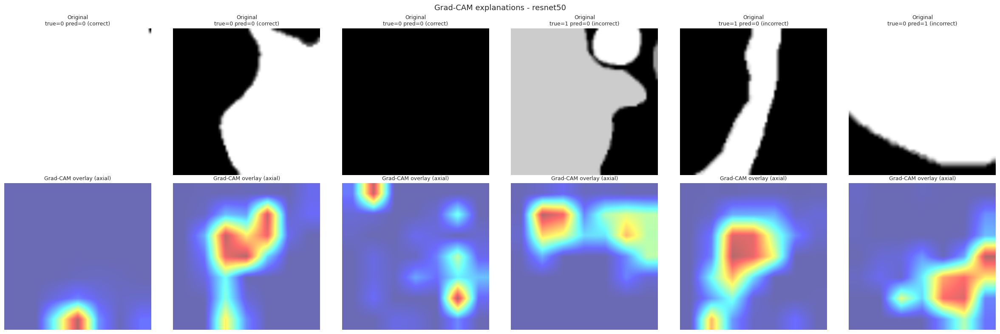

Saved /kaggle/working/figures/gradcam/resnet50_gradcam.png


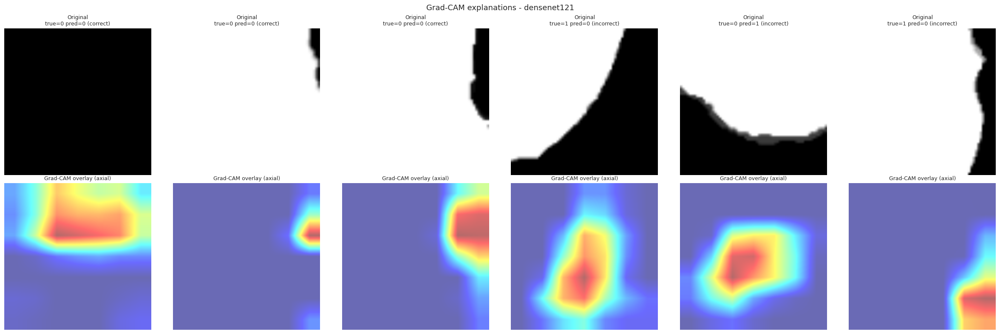

Saved /kaggle/working/figures/gradcam/densenet121_gradcam.png


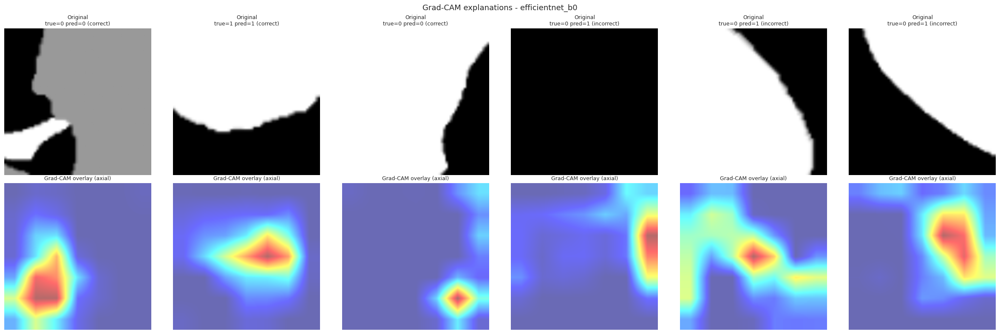

Saved /kaggle/working/figures/gradcam/efficientnet_b0_gradcam.png


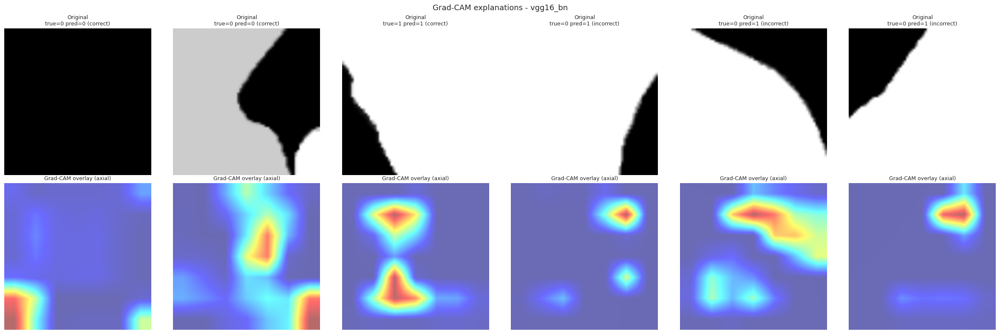

Saved /kaggle/working/figures/gradcam/vgg16_bn_gradcam.png


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


GRADCAM_FIG_DIR = "/kaggle/working/figures/gradcam"
os.makedirs(GRADCAM_FIG_DIR, exist_ok=True)


# The last convolutional layer to target for each architecture -
# Grad-CAM needs the last conv block's feature maps.
TARGET_LAYERS = {
   "resnet50": lambda m: [m.layer4[-1]],
   "densenet121": lambda m: [m.features[-1]],
   "efficientnet_b0": lambda m: [m.features[-1]],
   "vgg16_bn": lambda m: [m.features[-1]],
}


def load_trained_model(model_name):
   """Rebuild the architecture and load its best checkpoint."""
   model = build_model(model_name)
   checkpoint_path = f"{OUT_DIR}/{model_name}_best.pt"
   model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
   model.eval()
   return model

def run_gradcam_for_model(model_name, n_correct=3, n_incorrect=3):
   if not os.path.exists(f"{OUT_DIR}/{model_name}_test_predictions.csv"):
       print(f"No results found for {model_name}, skipping.")
       return

   model = load_trained_model(model_name)
   target_layers = TARGET_LAYERS[model_name](model)
   cam = GradCAM(model=model, target_layers=target_layers)

   preds_df = pd.read_csv(f"{OUT_DIR}/{model_name}_test_predictions.csv")
   correct_df = preds_df[preds_df["label"] == preds_df["pred"]]
   incorrect_df = preds_df[preds_df["label"] != preds_df["pred"]]

   correct_sample = correct_df.sample(min(n_correct, len(correct_df)), random_state=42)
   incorrect_sample = incorrect_df.sample(min(n_incorrect, len(incorrect_df)), random_state=42) \
       if len(incorrect_df) > 0 else incorrect_df

   combined = pd.concat([
       correct_sample.assign(status="correct"),
       incorrect_sample.assign(status="incorrect"),
   ])

   n = len(combined)
   if n == 0:
       print(f"No samples to visualize for {model_name}.")
       return

   fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
   if n == 1:
       axes = axes.reshape(2, 1)

   for col_idx, (_, row) in enumerate(combined.iterrows()):
       crop = torch.from_numpy(np.load(os.path.join(DATA_DIR, row["filename"]))).float()  # (3, H, W) in [0,1]
       input_tensor = to_model_input(crop).unsqueeze(0).to(DEVICE)
       axial = transforms.functional.resize(crop[0:1], [INPUT_SIZE, INPUT_SIZE], antialias=True)[0]
       axial = axial.clamp(0, 1).numpy()

       target_class = int(row["pred"])
       targets = [ClassifierOutputTarget(target_class)]
       grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

       rgb_img = np.stack([axial, axial, axial], axis=-1).astype(np.float32)  # HxWx3 for overlay
       cam_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

       axes[0, col_idx].imshow(axial, cmap="gray")
       axes[0, col_idx].set_title(f"Original\ntrue={row['label']} pred={row['pred']} ({row['status']})", fontsize=9)
       axes[0, col_idx].axis("off")

       axes[1, col_idx].imshow(cam_overlay)
       axes[1, col_idx].set_title("Grad-CAM overlay (axial)", fontsize=9)
       axes[1, col_idx].axis("off")

   plt.suptitle(f"Grad-CAM explanations - {model_name}", fontsize=13)
   plt.tight_layout()
   save_path = f"{GRADCAM_FIG_DIR}/{model_name}_gradcam.png"
   plt.savefig(save_path, dpi=150)
   plt.show()
   print(f"Saved {save_path}")


# Run for every model that has been trained so far
ALL_POSSIBLE_MODELS = ["resnet50", "densenet121", "efficientnet_b0", "vgg16_bn"]
trained_models = [
   name for name in ALL_POSSIBLE_MODELS
   if os.path.exists(f"{OUT_DIR}/{name}_best.pt")
]
print(f"Running Grad-CAM for: {trained_models}")

for name in trained_models:
   run_gradcam_for_model(name)

## Bundle all figures + result CSVs for download

In [20]:
import shutil


STAGE = "/kaggle/working/_zip_stage"
shutil.rmtree(STAGE, ignore_errors=True)
shutil.copytree("/kaggle/working/model_results", f"{STAGE}/figures")
shutil.copytree(OUT_DIR, f"{STAGE}/model_results", ignore=shutil.ignore_patterns("*.pt"))
zp = shutil.make_archive("/kaggle/working/phase1_completeResults", "zip", STAGE)
shutil.rmtree(STAGE)
print(f"Created {zp} ({os.path.getsize(zp) / 1e6:.1f} MB)")

Created /kaggle/working/phase1_completeResults.zip (628.5 MB)


## Phase 2 - Multimodal CT + PET characterization of lung cancer (LUNG-PET-CT-Dx)

In [2]:
# CELL 0 - setup and configuration
import os, sys, re, glob, json, time, copy, random, shutil, subprocess, warnings, unicodedata
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")


def _ensure(pkg):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", pkg, "-q"], check=False)


for _p in ("pydicom", "SimpleITK"):
    _ensure(_p)

# ============================== CONFIG ==============================
QUICK_TEST = False           # True: ~24 patients, 2 folds, 2 epochs (pipeline check). False = final run.
QUICK_N_PATIENTS = 24        # cohort size in quick mode (stratified random sample)
TASK = "adeno_vs_rest"       # or "adeno_vs_squamous"
SEED = 42
N_FOLDS = 2 if QUICK_TEST else 5
EPOCHS = 2 if QUICK_TEST else 25
BATCH_SIZE = 32
LR = 3e-4
SLICES_PER_PATIENT = 7       # annotated slices sampled per patient (patient prediction = mean over slices)
CROP_FOV_MM = 160.0          # physical side length of the square crop around the tumor box centre
CROP_PX = 128                # crop resolution (CT and PET resampled to the SAME grid)
CT_WIN = (-1000.0, 400.0)    # HU window -> [0, 1]
PET_SUV_MAX = 15.0           # SUV clipped to [0, PET_SUV_MAX] -> [0, 1]
RECOMPUTE_ANNOTATIONS = False  # True: ignore cached annotation check
SAVE_WEIGHTS = ["early", "intermediate", "cross_attn_md"]   # fold-0 weights kept for explainability

ROOT_CANDIDATE = "/kaggle/input/datasets/rangan2510/lung-pet-ct-dx"
RES_DIR = "/kaggle/working/phase2_results"
VOL_DIR = f"{RES_DIR}/volumes"
CROP_DIR = f"{RES_DIR}/crops"
WEIGHT_DIR = f"{RES_DIR}/weights"
FIG_DIR = "/kaggle/working/figures/phase2"
for _d in (RES_DIR, VOL_DIR, CROP_DIR, WEIGHT_DIR, FIG_DIR):
    os.makedirs(_d, exist_ok=True)
print(f"QUICK_TEST={QUICK_TEST} | TASK={TASK} | folds={N_FOLDS} | epochs={EPOCHS}")

QUICK_TEST=False | TASK=adeno_vs_rest | folds=5 | epochs=25


Dataset root: /kaggle/input/datasets/rangan2510/lung-pet-ct-dx
Series: 1295 | folders found: 1295 | missing: 0

Patients: 355 | with CT: 355 | with PET: 133 | CT+PET same study: 130
PET series types: {'PET WB Corrected': 133}

Subtype counts:
                 all_patients  ct_pet_paired
subtype                                    
Adenocarcinoma           251             93
LargeCell                  5              0
SmallCell                 38              9
Squamous                  61             28

Clinical missing values (paired cohort):
sex           1
age           1
weight_kg     1
t_stage       1
n_stage       1
m_stage       1
grade        80
smoking       1


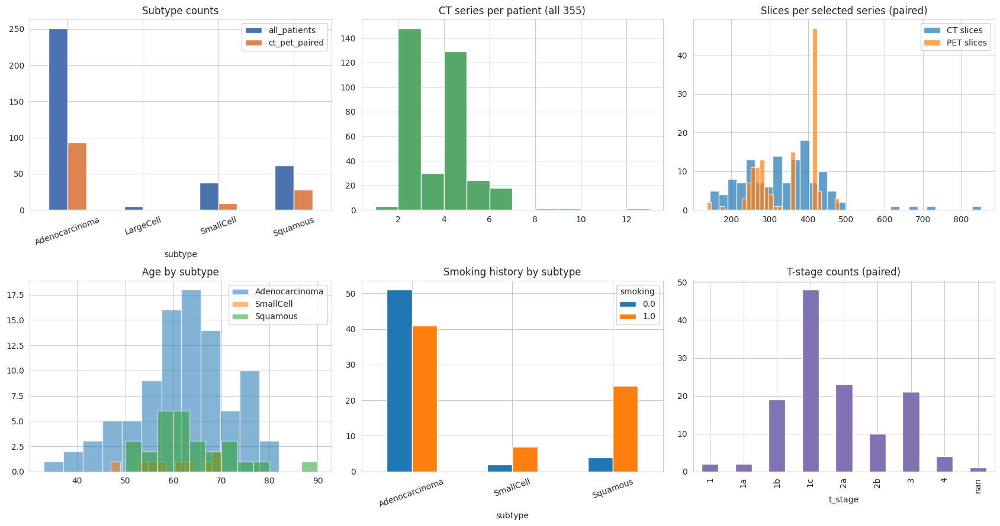

In [3]:
# CELL 1 - load dataset tables, build the CT+PET cohort, EDA part 1
SUBTYPE_MAP = {"A": "Adenocarcinoma", "B": "SmallCell", "E": "LargeCell", "G": "Squamous"}


def find_root():
    if os.path.exists(os.path.join(ROOT_CANDIDATE, "metadata.csv")):
        return ROOT_CANDIDATE
    for r, _, files in os.walk("/kaggle/input"):
        if "metadata.csv" in files and "statistics-clinical-20201221.xlsx" in files:
            return r
    raise FileNotFoundError("LUNG-PET-CT-Dx dataset not found under /kaggle/input - add it as notebook input.")


def resolve_series_dir(file_location, img_root):
    p = re.sub(r"^\./", "", str(file_location).replace("\\", "/"))
    parts = [x for x in p.split("/") if x]
    if parts and parts[0] == "Lung-PET-CT-Dx":
        parts = parts[1:]
    return os.path.join(img_root, *parts)


def load_clinical(root):
    clin = pd.read_excel(os.path.join(root, "statistics-clinical-20201221.xlsx"))
    clin.columns = [unicodedata.normalize("NFKC", str(c)).strip() for c in clin.columns]  # full-width 'M' in 'M-Stage'
    clin = clin.rename(columns={"NewPatientID": "patient_id", "Sex": "sex", "Age": "age", "weight (kg)": "weight_kg",
                                "T-Stage": "t_stage", "N-Stage": "n_stage", "M-Stage": "m_stage",
                                "Histopathological grading": "grade", "Smoking History": "smoking"})
    clin["patient_id"] = clin["patient_id"].astype(str).str.strip()
    return clin.drop(columns=[c for c in ["No."] if c in clin.columns])


def build_series_table(root):
    meta = pd.read_csv(os.path.join(root, "metadata.csv"))
    img_root = os.path.join(root, "Lung-PET-CT-Dx", "Lung-PET-CT-Dx")
    s = meta.rename(columns={"Series UID": "series_uid", "Study UID": "study_uid", "Study Date": "study_date",
                             "Series Description": "series_desc", "Modality": "modality",
                             "Number of Images": "n_images"}).copy()
    s["patient_id"] = s["Subject ID"].str.replace("Lung_Dx-", "", regex=False)
    s["series_dir"] = s["File Location"].apply(lambda x: resolve_series_dir(x, img_root))
    s["dir_exists"] = s["series_dir"].apply(os.path.isdir)
    s["study_date_dt"] = pd.to_datetime(s["study_date"], format="%m-%d-%Y", errors="coerce")
    return s[["patient_id", "series_uid", "study_uid", "study_date", "study_date_dt", "series_desc",
              "modality", "n_images", "series_dir", "dir_exists"]]


def pair_patients(s):
    """Patients with CT and PET in the SAME study; CT/PET series with most images (provisional rule)."""
    rows = []
    for pid, g in s.groupby("patient_id"):
        for study_uid, sg in g.sort_values("study_date_dt").groupby("study_uid", sort=False):
            ct, pt = sg[sg["modality"] == "CT"], sg[sg["modality"] == "PT"]
            if len(ct) and len(pt):
                c = ct.sort_values("n_images", ascending=False).iloc[0]
                p = pt.sort_values("n_images", ascending=False).iloc[0]
                rows.append({"patient_id": pid, "study_uid": study_uid, "study_date": c["study_date"],
                             "n_ct_series_in_study": len(ct), "n_pt_series_in_study": len(pt),
                             "ct_series_uid": c["series_uid"], "ct_desc": c["series_desc"], "ct_n_images": c["n_images"],
                             "ct_dir": c["series_dir"], "pt_series_uid": p["series_uid"], "pt_desc": p["series_desc"],
                             "pt_n_images": p["n_images"], "pt_dir": p["series_dir"]})
                break
    return pd.DataFrame(rows)


def add_subtype(df):
    df = df.copy()
    df["subtype_letter"] = df["patient_id"].str[0]
    df["subtype"] = df["subtype_letter"].map(SUBTYPE_MAP)
    return df


ROOT = find_root()
ANN_ROOT = os.path.join(ROOT, "Annotation", "Annotation")
series = build_series_table(ROOT)
clin = load_clinical(ROOT)
print(f"Dataset root: {ROOT}")
print(f"Series: {len(series)} | folders found: {series['dir_exists'].sum()} | missing: {(~series['dir_exists']).sum()}")

paired = pair_patients(series)
paired = add_subtype(paired).merge(clin, on="patient_id", how="left", validate="one_to_one")
all_patients = add_subtype(pd.DataFrame({"patient_id": sorted(series["patient_id"].unique())}))
ct_p, pt_p = set(series.loc[series.modality == "CT", "patient_id"]), set(series.loc[series.modality == "PT", "patient_id"])
print(f"\nPatients: {series['patient_id'].nunique()} | with CT: {len(ct_p)} | with PET: {len(pt_p)} | "
      f"CT+PET same study: {len(paired)}")
print("PET series types:", series.loc[series.modality == "PT", "series_desc"].value_counts().to_dict())
counts = pd.DataFrame({"all_patients": all_patients["subtype"].value_counts(),
                       "ct_pet_paired": paired["subtype"].value_counts()}).fillna(0).astype(int)
print("\nSubtype counts:\n", counts)
print("\nClinical missing values (paired cohort):")
print(paired[["sex", "age", "weight_kg", "t_stage", "n_stage", "m_stage", "grade", "smoking"]].isna().sum().to_string())

# ---- EDA 1 ----
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
counts.plot(kind="bar", ax=axes[0, 0], color=["#4C72B0", "#DD8452"]); axes[0, 0].set_title("Subtype counts")
axes[0, 0].tick_params(axis="x", rotation=20)
n_ct = series[series.modality == "CT"].groupby("patient_id").size()
axes[0, 1].hist(n_ct, bins=range(1, int(n_ct.max()) + 2), color="#55A868"); axes[0, 1].set_title("CT series per patient (all 355)")
axes[0, 2].hist(paired["ct_n_images"], bins=30, alpha=0.7, label="CT slices"); axes[0, 2].hist(paired["pt_n_images"], bins=30, alpha=0.7, label="PET slices")
axes[0, 2].set_title("Slices per selected series (paired)"); axes[0, 2].legend()
for sub in paired["subtype"].dropna().unique():
    axes[1, 0].hist(paired.loc[paired.subtype == sub, "age"].dropna(), bins=12, alpha=0.55, label=sub)
axes[1, 0].set_title("Age by subtype"); axes[1, 0].legend()
pd.crosstab(paired["subtype"], paired["smoking"]).plot(kind="bar", ax=axes[1, 1]); axes[1, 1].set_title("Smoking history by subtype")
axes[1, 1].tick_params(axis="x", rotation=20)
paired["t_stage"].astype(str).value_counts().sort_index().plot(kind="bar", ax=axes[1, 2], color="#8172B3"); axes[1, 2].set_title("T-stage counts (paired)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda1_cohort_overview.png", dpi=140); plt.show()


Annotation check for 130 patients with 32 threads
  annotation check 10/130 | 5.9 min | ~70.4 min left
  annotation check 20/130 | 5.9 min | ~32.2 min left
  annotation check 30/130 | 5.9 min | ~19.5 min left
  annotation check 40/130 | 7.2 min | ~16.1 min left
  annotation check 50/130 | 9.7 min | ~15.5 min left
  annotation check 60/130 | 9.7 min | ~11.3 min left
  annotation check 70/130 | 10.1 min | ~8.7 min left
  annotation check 80/130 | 10.3 min | ~6.4 min left
  annotation check 90/130 | 12.4 min | ~5.5 min left
  annotation check 100/130 | 13.6 min | ~4.1 min left
  annotation check 110/130 | 14.5 min | ~2.6 min left
  annotation check 120/130 | 14.5 min | ~1.2 min left
  annotation check 130/130 | 15.4 min | ~0.0 min left
CT series switched to the annotated series for 27 patients.

=== Label check: patient-ID prefix vs XML class letter (rows = boxes) ===
class_name      a  a0192     b     g
id_prefix                           
a           15725      9    21     4
b          

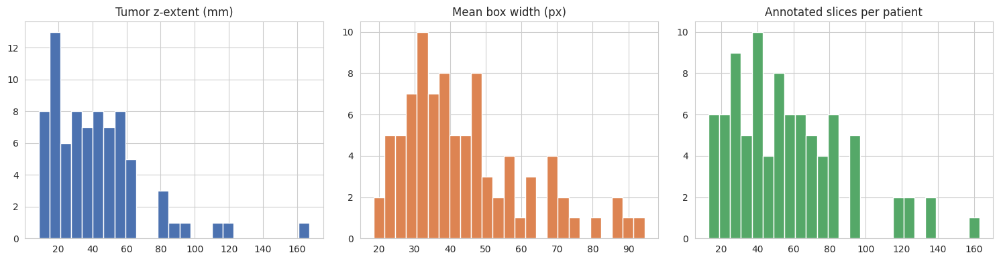


COHORT: 87 patients | label counts: {0: 63, 1: 24} (1 = squamous/small cell/large cell)


In [4]:
# CELL 2 - parse annotations, verify annotated CT series, tumor-extent EDA, define the cohort
def parse_annotation_xml(path):
    out = []
    for obj in ET.parse(path).getroot().iter("object"):
        bb = obj.find("bndbox")
        if bb is None:
            continue
        try:
            xmin, ymin, xmax, ymax = [int(float(bb.findtext(k))) for k in ("xmin", "ymin", "xmax", "ymax")]
        except (TypeError, ValueError):
            continue
        out.append(((obj.findtext("name") or "").strip().lower(), xmin, ymin, xmax, ymax))
    return out


def load_patient_boxes(ann_root, pid):
    rows = []
    for xml_path in sorted(glob.glob(os.path.join(ann_root, pid, "**", "*.xml"), recursive=True)):
        sop_uid = os.path.splitext(os.path.basename(xml_path))[0]   # XML file name = CT slice SOP Instance UID
        for name, x0, y0, x1, y1 in parse_annotation_xml(xml_path):
            rows.append({"patient_id": pid, "sop_uid": sop_uid, "class_name": name,
                         "xmin": x0, "ymin": y0, "xmax": x1, "ymax": y1})
    return pd.DataFrame(rows)


def pick_annotated_series(found):
    if not found:
        return None, 0
    counts = pd.Series([v["series_uid"] for v in found.values()]).value_counts()
    return counts.index[0], int(counts.iloc[0])


def roi_summary(matched):
    if matched.empty:
        return {}
    z = matched["ipp_z"]
    return {"n_annotated_slices": int(matched["sop_uid"].nunique()),
            "max_boxes_per_slice": int(matched.groupby("sop_uid").size().max()),
            "z_min_mm": float(z.min()), "z_max_mm": float(z.max()), "z_extent_mm": float(z.max() - z.min()),
            "mean_box_w_px": float((matched["xmax"] - matched["xmin"]).mean()),
            "mean_box_h_px": float((matched["ymax"] - matched["ymin"]).mean())}


def locate_slices(sop_uids, ct_series_rows, preferred_series_uid):
    """Header-only DICOM read: which CT series holds each annotated SOP UID (+ slice position)."""
    import pydicom
    remaining, found = set(sop_uids), {}
    for r in sorted(ct_series_rows, key=lambda r: r["series_uid"] != preferred_series_uid):
        for f in sorted(glob.glob(os.path.join(r["series_dir"], "*.dcm"))):
            if not remaining:
                break
            try:
                d = pydicom.dcmread(f, stop_before_pixels=True,
                                    specific_tags=["SOPInstanceUID", "ImagePositionPatient", "InstanceNumber"])
            except Exception:
                continue
            sop = str(d.SOPInstanceUID)
            if sop in remaining:
                ipp = [float(x) for x in getattr(d, "ImagePositionPatient", [np.nan] * 3)]
                found[sop] = {"series_uid": r["series_uid"], "ipp_x": ipp[0], "ipp_y": ipp[1], "ipp_z": ipp[2],
                              "instance_number": int(getattr(d, "InstanceNumber", -1))}
                remaining.discard(sop)
        if len(remaining) <= 0.1 * len(sop_uids):
            break
    return found


_sfx = "_quick" if QUICK_TEST else ""          # quick runs check only a sample -> never reuse their cache for the full run
V2_CSV, BOXES_CSV, SUMM_CSV = (f"{RES_DIR}/paired_patients_v2{_sfx}.csv", f"{RES_DIR}/annotation_boxes{_sfx}.csv",
                               f"{RES_DIR}/annotation_patient_summary{_sfx}.csv")
LOG_CSV = f"{RES_DIR}/preprocess_log.csv"
ANN_THREADS = 32                               # header reads are I/O bound (network disk) -> threads overlap the waits


def check_patient(row):
    """Find which CT series holds this patient's annotated slices (header-only reads)."""
    pid = row["patient_id"]
    boxes = load_patient_boxes(ANN_ROOT, pid)
    summ = {"patient_id": pid, "selected_ct_series_uid": row["ct_series_uid"], "n_xml": 0,
            "n_boxes": len(boxes), "match_frac": 0.0, "annot_series_uid": None}
    if not boxes.empty:
        sops = boxes["sop_uid"].unique().tolist()
        summ["n_xml"] = len(sops)
        found = locate_slices(sops, ct_series[ct_series["patient_id"] == pid].to_dict("records"), row["ct_series_uid"])
        annot_uid, hits = pick_annotated_series(found)
        summ["match_frac"], summ["annot_series_uid"], summ["n_matched"] = round(hits / len(sops), 3), annot_uid, hits
        info = (pd.DataFrame.from_dict(found, orient="index").rename_axis("sop_uid").reset_index()
                if found else pd.DataFrame(columns=["sop_uid"]))
        boxes = boxes.merge(info, on="sop_uid", how="left")
        if annot_uid is not None:
            summ.update(roi_summary(boxes[boxes["series_uid"] == annot_uid]))
            summ["annot_ct_dir"] = series_by_uid.loc[annot_uid, "series_dir"]
            summ["annot_study_uid"] = series_by_uid.loc[annot_uid, "study_uid"]
            summ["annot_n_images"] = int(series_by_uid.loc[annot_uid, "n_images"])
        summ["class_names"] = ",".join(sorted(set(boxes["class_name"])))
    return boxes, summ


MIN_MATCHED_SLICES = 3     # annotated slices that must be found in the CT of the PET study (crops use up to 7)

if not RECOMPUTE_ANNOTATIONS and all(os.path.exists(p) for p in (BOXES_CSV, SUMM_CSV)):
    print("Using cached annotation check (set RECOMPUTE_ANNOTATIONS=True to redo).")
    boxes_df, summ_df = pd.read_csv(BOXES_CSV), pd.read_csv(SUMM_CSV)
else:
    from concurrent.futures import ThreadPoolExecutor
    ct_series = series[series["modality"] == "CT"]
    series_by_uid = series.set_index("series_uid")
    to_check = paired
    if QUICK_TEST:                             # ~3x the quick cohort, stratified by subtype, is enough to sample from
        to_check = (paired.groupby("subtype", group_keys=False)
                    .apply(lambda g: g.sample(min(len(g), max(3, round(3 * QUICK_N_PATIENTS * len(g) / len(paired)))),
                                              random_state=SEED)))
    print(f"Annotation check for {len(to_check)} patients with {ANN_THREADS} threads")
    all_boxes, summaries, t0 = [], [], time.time()
    with ThreadPoolExecutor(ANN_THREADS) as ex:
        for k, (boxes, summ) in enumerate(ex.map(check_patient, [r for _, r in to_check.iterrows()]), 1):
            if not boxes.empty:
                all_boxes.append(boxes)
            summaries.append(summ)
            if k % 10 == 0 or k == len(to_check):
                el = time.time() - t0
                print(f"  annotation check {k}/{len(to_check)} | {el / 60:.1f} min | ~{el / k * (len(to_check) - k) / 60:.1f} min left")

    boxes_df = pd.concat(all_boxes, ignore_index=True)
    summ_df = pd.DataFrame(summaries).merge(paired[["patient_id", "subtype_letter", "subtype", "study_uid"]], on="patient_id", how="left")
    summ_df["matches_selected_ct"] = summ_df["annot_series_uid"] == summ_df["selected_ct_series_uid"]
    summ_df["annot_in_pet_study"] = summ_df["annot_study_uid"] == summ_df["study_uid"]
    boxes_df.to_csv(BOXES_CSV, index=False); summ_df.to_csv(SUMM_CSV, index=False)

# usable for fusion = enough annotated slices located in a CT series of the same study as the PET
if "n_matched" not in summ_df:                 # caches written before n_matched was stored
    summ_df["n_matched"] = (summ_df["match_frac"] * summ_df["n_xml"]).round()
summ_df["annot_in_pet_study"] = summ_df["annot_in_pet_study"].fillna(False).astype(bool)
summ_df["fusion_ok"] = (summ_df["n_matched"].fillna(0) >= MIN_MATCHED_SLICES) & summ_df["annot_in_pet_study"]

v2 = paired.merge(summ_df[["patient_id", "annot_series_uid", "annot_ct_dir", "annot_n_images", "match_frac", "n_matched",
                           "matches_selected_ct", "annot_in_pet_study", "fusion_ok"]], on="patient_id", how="left")
v2["fusion_ok"] = v2["fusion_ok"].fillna(False).astype(bool)
v2["ct_dir_orig"] = v2["ct_dir"]
switch = v2["fusion_ok"] & ~v2["matches_selected_ct"].fillna(True).astype(bool)
v2.loc[switch, ["ct_series_uid", "ct_dir", "ct_n_images"]] = v2.loc[switch, ["annot_series_uid", "annot_ct_dir", "annot_n_images"]].values
print(f"CT series switched to the annotated series for {int(switch.sum())} patients.")
if os.path.exists(V2_CSV):                     # volumes / crops built from a different CT series are stale
    _prev = pd.read_csv(V2_CSV).set_index("patient_id")["ct_series_uid"]
    stale = [p for p, uid in zip(v2["patient_id"], v2["ct_series_uid"]) if p in _prev.index and _prev[p] != uid]
    for pid in stale:
        for f in (f"{VOL_DIR}/{pid}_ct.nii.gz", f"{CROP_DIR}/{pid}.npz"):
            if os.path.exists(f):
                os.remove(f)
    if stale and os.path.exists(LOG_CSV):
        _log = pd.read_csv(LOG_CSV); _log[~_log["patient_id"].isin(stale)].to_csv(LOG_CSV, index=False)
v2.to_csv(V2_CSV, index=False)

# ---- label check and EDA 2 ----
print("\n=== Label check: patient-ID prefix vs XML class letter (rows = boxes) ===")
_b = boxes_df.copy(); _b["id_prefix"] = _b["patient_id"].str[0].str.lower()
print(pd.crosstab(_b["id_prefix"], _b["class_name"]))
print(f"Patients with a box whose class letter != ID prefix: {_b[_b['id_prefix'] != _b['class_name']]['patient_id'].nunique()}")
n = len(summ_df)
print(f"\nShare of annotated slices found in one CT series: median {summ_df['match_frac'].median():.2f} "
      f"(quartiles {summ_df['match_frac'].quantile(0.25):.2f} / {summ_df['match_frac'].quantile(0.75):.2f})")
print(f">= {MIN_MATCHED_SLICES} annotated slices found: {int((summ_df['n_matched'].fillna(0) >= MIN_MATCHED_SLICES).sum())}/{n} | "
      f"annotated CT is in the PET study: {int(summ_df['annot_in_pet_study'].sum())}/{n} | "
      f"usable (fusion_ok): {int(summ_df['fusion_ok'].sum())}/{n}")
ok = summ_df[summ_df["fusion_ok"]]
print(ok.groupby("subtype")["fusion_ok"].count().rename("usable_patients").to_string())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(ok["z_extent_mm"].dropna(), bins=25, color="#4C72B0"); axes[0].set_title("Tumor z-extent (mm)")
axes[1].hist(ok["mean_box_w_px"].dropna(), bins=25, color="#DD8452"); axes[1].set_title("Mean box width (px)")
axes[2].hist(ok["n_annotated_slices"].dropna(), bins=25, color="#55A868"); axes[2].set_title("Annotated slices per patient")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda2_tumor_extent.png", dpi=140); plt.show()


# ---- define the working cohort + labels ----
def make_labels(df):
    df = df.copy()
    if TASK == "adeno_vs_rest":
        df["label"] = (df["subtype"] != "Adenocarcinoma").astype(int)
    elif TASK == "adeno_vs_squamous":
        df = df[df["subtype"].isin(["Adenocarcinoma", "Squamous"])].copy()
        df["label"] = (df["subtype"] == "Squamous").astype(int)
    else:
        raise ValueError(TASK)
    return df


cohort = make_labels(v2[v2["fusion_ok"]].reset_index(drop=True))
if QUICK_TEST and len(cohort) > QUICK_N_PATIENTS:
    parts = [g.sample(min(len(g), max(5, round(QUICK_N_PATIENTS * len(g) / len(cohort)))), random_state=SEED)
             for _, g in cohort.groupby("label")]
    cohort = pd.concat(parts).sort_values("patient_id").reset_index(drop=True)
print(f"\nCOHORT: {len(cohort)} patients | label counts: {cohort['label'].value_counts().sort_index().to_dict()} "
      f"(1 = {'squamous/small cell/large cell' if TASK == 'adeno_vs_rest' else 'squamous'})")

In [5]:
# CELL 3 - DICOM -> CT (HU) and PET (SUV) NIfTI volumes  (resumable, one failure never stops the run)
def parse_dicom_time(value):
    s = str(value).strip()
    whole, frac = (s.split(".", 1)[0], float("0." + s.split(".", 1)[1])) if "." in s else (s, 0.0)
    whole = whole.ljust(6, "0")
    return int(whole[0:2]) * 3600 + int(whole[2:4]) * 60 + int(whole[4:6]) + frac


def suv_bw_factor(weight_kg, total_dose_bq, half_life_s, injection_time_s, scan_time_s, decay_to_scan=True):
    """Multiply activity concentration (Bq/mL) by this factor to obtain body-weight SUV."""
    if decay_to_scan:
        dt = scan_time_s - injection_time_s
        if dt < 0:
            dt += 86400.0
        dose = total_dose_bq * 2.0 ** (-dt / half_life_s)
    else:
        dose = total_dose_bq
    return (weight_kg * 1000.0) / dose


def sort_and_geometry(positions, iop, pixel_spacing):
    iop = np.asarray(iop, dtype=float)
    row_dir, col_dir = iop[:3], iop[3:]
    normal = np.cross(row_dir, col_dir)
    pos = np.asarray(positions, dtype=float)
    proj = pos @ normal
    order = np.argsort(proj, kind="stable")
    proj_sorted = proj[order]
    keep = np.concatenate([[True], np.diff(proj_sorted) > 1e-3])      # drop duplicated slice positions
    order, proj_sorted = order[keep], proj_sorted[keep]
    dz = np.diff(proj_sorted)
    gap = float(np.median(dz)) if len(dz) else 1.0
    dev = float(np.max(np.abs(dz - gap))) if len(dz) else 0.0
    spacing = (float(pixel_spacing[1]), float(pixel_spacing[0]), gap)  # DICOM PixelSpacing = [row(y), col(x)]
    direction = (row_dir[0], col_dir[0], normal[0], row_dir[1], col_dir[1], normal[1], row_dir[2], col_dir[2], normal[2])
    return order, spacing, tuple(float(x) for x in pos[order[0]]), tuple(float(x) for x in direction), dev


def read_series(series_dir):
    import pydicom
    files = sorted(glob.glob(os.path.join(series_dir, "*.dcm"))) or \
        sorted(f for f in glob.glob(os.path.join(series_dir, "*")) if os.path.isfile(f))
    dsets = []
    for f in files:
        d = pydicom.dcmread(f, force=True)
        if hasattr(d, "ImagePositionPatient") and hasattr(d, "PixelData"):
            dsets.append(d)
    if not dsets:
        raise ValueError(f"no usable DICOM slices in {series_dir}")
    order, spacing, origin, direction, dev = sort_and_geometry([d.ImagePositionPatient for d in dsets],
                                                               dsets[0].ImageOrientationPatient, dsets[0].PixelSpacing)
    dsets = [dsets[i] for i in order]
    vol = np.stack([d.pixel_array.astype(np.float32) * float(getattr(d, "RescaleSlope", 1.0)) +
                    float(getattr(d, "RescaleIntercept", 0.0)) for d in dsets], axis=0)   # per-slice rescale
    return vol, dsets, spacing, origin, direction, dev


def to_sitk(vol, spacing, origin, direction, dtype):
    import SimpleITK as sitk
    img = sitk.GetImageFromArray(vol.astype(dtype))
    img.SetSpacing(spacing); img.SetOrigin(origin); img.SetDirection(direction)
    return img


def pet_to_suv(vol, dsets, fallback_weight_kg=None):
    d0 = dsets[0]
    units = str(getattr(d0, "Units", "")).strip().upper()
    info = {"pet_units": units}
    if units == "GML":
        info["suv_method"] = "units_gml"; return vol, info
    if units == "CNTS":                                    # Philips private SUV scale factor
        scale = d0.get((0x7053, 0x1000))
        if scale is None:
            raise ValueError("PET units CNTS without Philips SUV scale factor")
        info["suv_method"] = "philips_private"; return vol * float(scale.value), info
    if units != "BQML":
        raise ValueError(f"unsupported PET units '{units}'")
    weight = float(getattr(d0, "PatientWeight", 0) or 0)
    info["weight_source"] = "dicom"
    if not weight:
        if fallback_weight_kg is None or pd.isna(fallback_weight_kg):
            raise ValueError("no patient weight in DICOM or clinical sheet")
        weight, info["weight_source"] = float(fallback_weight_kg), "clinical_sheet"
    rp = d0.RadiopharmaceuticalInformationSequence[0]
    dose, half_life = float(rp.RadionuclideTotalDose), float(rp.RadionuclideHalfLife)
    inj_t = parse_dicom_time(rp.RadiopharmaceuticalStartTime)
    times = [parse_dicom_time(d.AcquisitionTime) for d in dsets if hasattr(d, "AcquisitionTime")]
    scan_t = min(times) if times else parse_dicom_time(d0.SeriesTime)
    decay_corr = str(getattr(d0, "DecayCorrection", "START")).strip().upper()
    factor = suv_bw_factor(weight, dose, half_life, inj_t, scan_t, decay_to_scan=(decay_corr != "ADMIN"))
    info.update({"suv_method": "bqml_bodyweight", "weight_kg": weight, "dose_mbq": dose / 1e6,
                 "uptake_min": ((scan_t - inj_t) % 86400) / 60.0, "decay_correction": decay_corr})
    return vol * factor, info


def process_patient(row):
    import SimpleITK as sitk
    t0, pid = time.time(), row["patient_id"]
    ct, ct_ds, ct_sp, ct_org, ct_dir, ct_dev = read_series(row["ct_dir"])
    pet, pet_ds, pet_sp, pet_org, pet_dir, pet_dev = read_series(row["pt_dir"])
    suv, info = pet_to_suv(pet, pet_ds, fallback_weight_kg=row.get("weight_kg"))
    ct_img = to_sitk(np.clip(ct, -1024, 3071), ct_sp, ct_org, ct_dir, np.int16)
    pet_img = to_sitk(suv, pet_sp, pet_org, pet_dir, np.float32)
    res = sitk.Resample(pet_img, ct_img, sitk.Transform(), sitk.sitkLinear, -1.0, sitk.sitkFloat32)
    coverage = float((sitk.GetArrayFromImage(res) > -0.5).mean())          # share of the CT grid inside the PET FOV
    sitk.WriteImage(ct_img, f"{VOL_DIR}/{pid}_ct.nii.gz")
    sitk.WriteImage(pet_img, f"{VOL_DIR}/{pid}_pet_suv.nii.gz")
    rec = {"patient_id": pid, "status": "ok", "error": ""}
    rec.update(info)
    rec.update({"ct_shape_zyx": str(ct.shape), "ct_spacing_xyz": str(tuple(round(x, 3) for x in ct_sp)),
                "pet_shape_zyx": str(pet.shape), "pet_spacing_xyz": str(tuple(round(x, 3) for x in pet_sp)),
                "same_frame_of_reference": getattr(ct_ds[0], "FrameOfReferenceUID", "ct") == getattr(pet_ds[0], "FrameOfReferenceUID", "pet"),
                "suv_max": float(suv.max()), "suv_p999": float(np.percentile(suv, 99.9)),
                "ct_pet_coverage": round(coverage, 3), "seconds": round(time.time() - t0, 1)})
    return rec


PREP_WORKERS = os.cpu_count() or 1


def _safe_process_patient(row):
    """Worker wrapper: one failed patient never stops the run."""
    try:
        return process_patient(row)
    except Exception as e:
        return {"patient_id": row["patient_id"], "status": "failed", "error": f"{type(e).__name__}: {e}"}


def run_preprocessing(rows):
    records = {}
    if os.path.exists(LOG_CSV):
        for r in pd.read_csv(LOG_CSV).to_dict("records"):
            pid = r["patient_id"]
            if r.get("status") == "ok" and os.path.exists(f"{VOL_DIR}/{pid}_ct.nii.gz") and os.path.exists(f"{VOL_DIR}/{pid}_pet_suv.nii.gz"):
                records[pid] = r
    todo = [r for _, r in rows.iterrows() if r["patient_id"] not in records]
    print(f"DICOM conversion: {len(records)} already done, {len(todo)} to process with {PREP_WORKERS} workers")
    import multiprocessing as mp
    import SimpleITK as sitk
    sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(1)          # one thread per worker process
    t0 = time.time()
    with mp.get_context("fork").Pool(PREP_WORKERS) as pool:
        for k, rec in enumerate(pool.imap_unordered(_safe_process_patient, todo), 1):
            if rec["status"] == "ok":
                print(f"  [{k}/{len(todo)}] {rec['patient_id']} ok  SUVmax={rec['suv_max']:.1f}  coverage={rec['ct_pet_coverage']}  ({rec['seconds']}s)"
                      f" | ~{(time.time() - t0) / k * (len(todo) - k) / 60:.0f} min left")
            else:
                print(f"  [{k}/{len(todo)}] {rec['patient_id']} FAILED  {rec['error']}")
            records[rec["patient_id"]] = rec
            pd.DataFrame(list(records.values())).to_csv(LOG_CSV, index=False)   # resumable after a restart
    sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(os.cpu_count() or 1)
    return pd.DataFrame(list(records.values()))


prep_log = run_preprocessing(cohort)
prep_log = prep_log[prep_log["patient_id"].isin(cohort["patient_id"])]
bad = prep_log[prep_log["status"] != "ok"]
if len(bad):
    print("\nFailed patients (dropped from the cohort):"); print(bad[["patient_id", "error"]].to_string(index=False))
cohort = cohort[cohort["patient_id"].isin(prep_log.loc[prep_log["status"] == "ok", "patient_id"])].reset_index(drop=True)
ok_log = prep_log[prep_log["status"] == "ok"]
print(f"\nCohort after DICOM conversion: {len(cohort)} patients")
print(f"SUVmax median {ok_log['suv_max'].median():.1f} (min {ok_log['suv_max'].min():.1f}, max {ok_log['suv_max'].max():.1f}) | "
      f"suspicious (<1 or >60): {((ok_log['suv_max'] < 1) | (ok_log['suv_max'] > 60)).sum()}")
print(f"Same FrameOfReferenceUID: {int(ok_log['same_frame_of_reference'].sum())}/{len(ok_log)} | "
      f"CT coverage by PET < 90%: {(ok_log['ct_pet_coverage'] < 0.9).sum()}")
print("PET units / SUV method:", ok_log[["pet_units", "suv_method"]].value_counts().to_dict())

DICOM conversion: 0 already done, 87 to process with 4 workers
  [1/87] A0166 ok  SUVmax=16.7  coverage=1.0  (89.9s) | ~129 min left
  [2/87] A0167 ok  SUVmax=28.5  coverage=1.0  (92.7s) | ~66 min left
  [3/87] A0169 ok  SUVmax=31.3  coverage=1.0  (98.3s) | ~46 min left
  [4/87] A0165 ok  SUVmax=124.2  coverage=1.0  (104.4s) | ~36 min left
  [5/87] A0170 FAILED  ValueError: no usable DICOM slices in /kaggle/input/datasets/rangan2510/lung-pet-ct-dx/Lung-PET-CT-Dx/Lung-PET-CT-Dx/Lung_Dx-A0170/12-02-2010-NA-PET03CBMWholebodyFirstHead Adult-02190/16.000000-Range-CT WB  1.0  B30f-Tra-ALPHA Range-65492
  [6/87] A0171 ok  SUVmax=10.5  coverage=1.0  (87.2s) | ~41 min left
  [7/87] A0174 ok  SUVmax=13.5  coverage=1.0  (103.9s) | ~40 min left
  [8/87] A0173 ok  SUVmax=20.5  coverage=1.0  (115.3s) | ~35 min left
  [9/87] A0175 ok  SUVmax=16.9  coverage=1.0  (100.9s) | ~31 min left
  [10/87] A0176 ok  SUVmax=19.5  coverage=1.0  (110.6s) | ~37 min left
  [11/87] A0177 ok  SUVmax=8.8  coverage=1.0  

In [6]:
# CELL 4 - aligned CT/PET tumor crops (+ simple ROI features); cached per patient
def make_ref(ct_img, center_phys, fov, npx):
    """Reference grid: npx x npx x 1, in-plane spacing fov/npx, centred on `center_phys`, CT orientation."""
    import SimpleITK as sitk
    D = np.array(ct_img.GetDirection()).reshape(3, 3)
    sp = (fov / npx, fov / npx, float(ct_img.GetSpacing()[2]))
    half = (npx - 1) / 2.0
    origin = np.array(center_phys) - D[:, 0] * sp[0] * half - D[:, 1] * sp[1] * half
    ref = sitk.Image(npx, npx, 1, sitk.sitkFloat32)
    ref.SetSpacing(sp); ref.SetOrigin(tuple(float(v) for v in origin)); ref.SetDirection(ct_img.GetDirection())
    return ref


def select_boxes(boxes_p, n_slices):
    """One (largest) box per annotated slice; pick n slices evenly over the central 80% of the tumor extent."""
    b = boxes_p.dropna(subset=["ipp_z"]).copy()
    b["area"] = (b.xmax - b.xmin) * (b.ymax - b.ymin)
    b = b.sort_values("area", ascending=False).drop_duplicates("sop_uid").sort_values("ipp_z").reset_index(drop=True)
    m = len(b)
    if m <= n_slices:
        return b
    lo, hi = int(0.1 * (m - 1)), int(round(0.9 * (m - 1)))
    return b.iloc[np.unique(np.round(np.linspace(lo, hi, n_slices)).astype(int))]


def extract_patient_crops(pid, boxes_p):
    import SimpleITK as sitk
    ct = sitk.ReadImage(f"{VOL_DIR}/{pid}_ct.nii.gz")
    pet = sitk.ReadImage(f"{VOL_DIR}/{pid}_pet_suv.nii.gz")
    sx, sy = ct.GetSpacing()[0], ct.GetSpacing()[1]
    ppm = CROP_PX / CROP_FOV_MM
    yy, xx = np.mgrid[0:CROP_PX, 0:CROP_PX]
    c = (CROP_PX - 1) / 2.0
    cts, pets, feats = [], [], []
    for r in select_boxes(boxes_p, SLICES_PER_PATIENT).itertuples():
        cont = ct.TransformPhysicalPointToContinuousIndex((float(r.ipp_x), float(r.ipp_y), float(r.ipp_z)))
        k = int(np.clip(round(cont[2]), 0, ct.GetSize()[2] - 1))
        center = ct.TransformContinuousIndexToPhysicalPoint(((r.xmin + r.xmax) / 2.0, (r.ymin + r.ymax) / 2.0, float(k)))
        ref = make_ref(ct, center, CROP_FOV_MM, CROP_PX)
        ct_s = sitk.GetArrayFromImage(sitk.Resample(ct, ref, sitk.Transform(), sitk.sitkLinear, -1024.0, sitk.sitkFloat32))[0]
        pet_s = sitk.GetArrayFromImage(sitk.Resample(pet, ref, sitk.Transform(), sitk.sitkLinear, 0.0, sitk.sitkFloat32))[0]
        hw, hh = max(1.0, 0.5 * (r.xmax - r.xmin) * sx * ppm), max(1.0, 0.5 * (r.ymax - r.ymin) * sy * ppm)
        mask = (np.abs(xx - c) <= hw) & (np.abs(yy - c) <= hh)               # tumor box in crop pixels
        feats.append({"suv_max": pet_s[mask].max(), "suv_mean": pet_s[mask].mean(), "suv_std": pet_s[mask].std(),
                      "hu_mean": ct_s[mask].mean(), "hu_std": ct_s[mask].std(),
                      "box_w_mm": (r.xmax - r.xmin) * sx, "box_h_mm": (r.ymax - r.ymin) * sy})
        cts.append(np.clip((ct_s - CT_WIN[0]) / (CT_WIN[1] - CT_WIN[0]), 0, 1).astype(np.float16))
        pets.append(np.clip(pet_s / PET_SUV_MAX, 0, 1).astype(np.float16))
    f = pd.DataFrame(feats)
    patient_feat = {"suv_max": f.suv_max.max(), "suv_mean": f.suv_mean.mean(), "suv_std": f.suv_std.mean(),
                    "hu_mean": f.hu_mean.mean(), "hu_std": f.hu_std.mean(),
                    "box_w_mm": f.box_w_mm.max(), "box_h_mm": f.box_h_mm.max(),
                    "z_extent_mm": float(boxes_p["ipp_z"].max() - boxes_p["ipp_z"].min()),
                    "n_annotated_slices": int(boxes_p["sop_uid"].nunique())}
    np.savez_compressed(f"{CROP_DIR}/{pid}.npz", ct=np.stack(cts), pet=np.stack(pets),
                        feat_json=np.array(json.dumps({k: float(v) for k, v in patient_feat.items()})))


crop_fail = []
todo = [r for _, r in cohort.iterrows() if not os.path.exists(f"{CROP_DIR}/{r['patient_id']}.npz")]
print(f"Crop extraction: {len(cohort) - len(todo)} cached, {len(todo)} to build")
for k, row in enumerate(todo):
    try:
        bp = boxes_df[(boxes_df["patient_id"] == row["patient_id"]) & (boxes_df["series_uid"] == row["annot_series_uid"])]
        extract_patient_crops(row["patient_id"], bp)
    except Exception as e:
        crop_fail.append((row["patient_id"], f"{type(e).__name__}: {e}")); print(f"  {row['patient_id']} FAILED {crop_fail[-1][1]}")
    if (k + 1) % 10 == 0:
        print(f"  crops {k + 1}/{len(todo)}")

CROPS, FEATS = {}, {}
for pid in cohort["patient_id"]:
    pth = f"{CROP_DIR}/{pid}.npz"
    if os.path.exists(pth):
        z = np.load(pth)
        CROPS[pid] = (z["ct"].astype(np.float32), z["pet"].astype(np.float32))
        FEATS[pid] = json.loads(str(z["feat_json"]))
cohort = cohort[cohort["patient_id"].isin(CROPS)].reset_index(drop=True)
print(f"\nCrops ready for {len(cohort)} patients | total slices: {sum(v[0].shape[0] for v in CROPS.values())} | "
      f"label counts: {cohort['label'].value_counts().sort_index().to_dict()}")

Crop extraction: 0 cached, 78 to build
  crops 10/78
  crops 20/78
  crops 30/78
  crops 40/78
  crops 50/78
  crops 60/78
  crops 70/78

Crops ready for 78 patients | total slices: 546 | label counts: {0: 59, 1: 19}


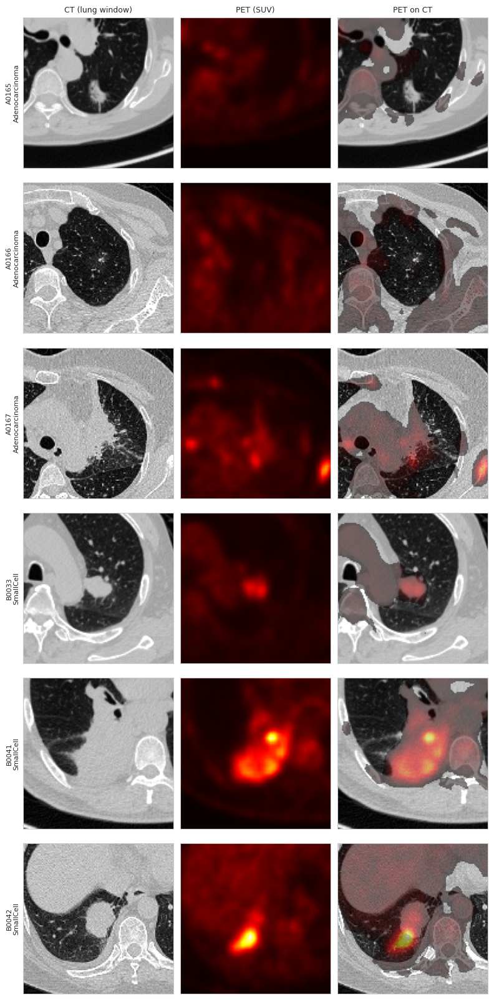

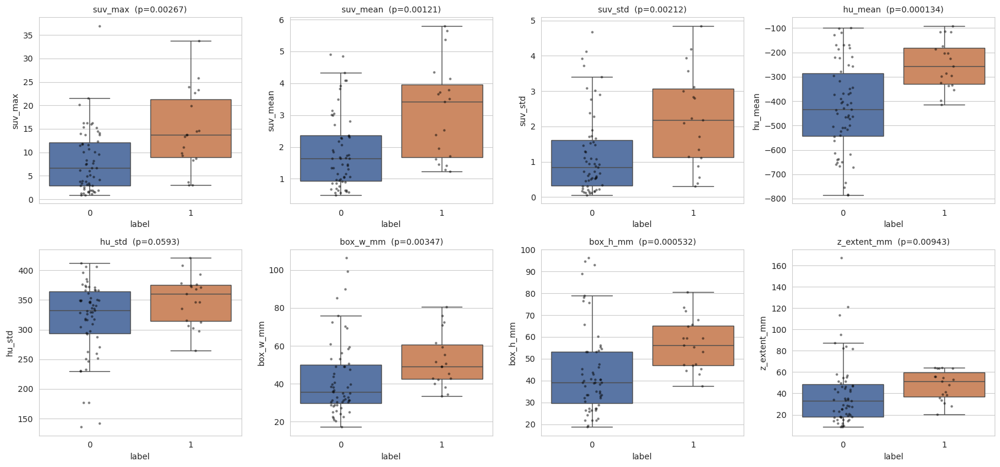

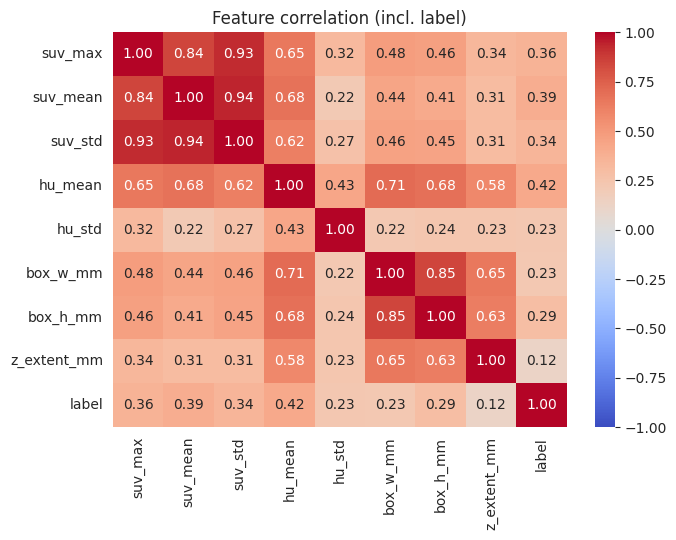

In [7]:
# CELL 5 - EDA on crops and tumor features
from scipy.stats import mannwhitneyu

fe = pd.DataFrame.from_dict(FEATS, orient="index").rename_axis("patient_id").reset_index()
fe = fe.merge(cohort[["patient_id", "label", "subtype"]], on="patient_id")

# --- montage: CT | PET | PET-on-CT overlay, 3 patients per class (middle slice) ---
rows_plot = []
for lab in (0, 1):
    rows_plot += cohort[cohort["label"] == lab]["patient_id"].head(3).tolist()
fig, axes = plt.subplots(len(rows_plot), 3, figsize=(8, 2.7 * len(rows_plot)))
axes = np.atleast_2d(axes)
for i, pid in enumerate(rows_plot):
    ct, pet = CROPS[pid]; j = ct.shape[0] // 2
    axes[i, 0].imshow(ct[j], cmap="gray", vmin=0, vmax=1)
    axes[i, 1].imshow(pet[j] * PET_SUV_MAX, cmap="hot", vmin=0, vmax=PET_SUV_MAX)
    axes[i, 2].imshow(ct[j], cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(np.ma.masked_less(pet[j] * PET_SUV_MAX, 1.0), cmap="hot", alpha=0.5, vmin=1, vmax=PET_SUV_MAX)
    sub = cohort.loc[cohort.patient_id == pid, "subtype"].iloc[0]
    axes[i, 0].set_ylabel(f"{pid}\n{sub}", fontsize=8)
    for a in axes[i]:
        a.set_xticks([]); a.set_yticks([])
for a, t in zip(axes[0], ["CT (lung window)", "PET (SUV)", "PET on CT"]):
    a.set_title(t, fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda3_crop_montage.png", dpi=140); plt.show()

# --- do the simple tumor features separate the classes? (Mann-Whitney U) ---
feat_cols = ["suv_max", "suv_mean", "suv_std", "hu_mean", "hu_std", "box_w_mm", "box_h_mm", "z_extent_mm"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.boxplot(data=fe, x="label", y=col, ax=ax, palette=["#4C72B0", "#DD8452"], showfliers=False)
    sns.stripplot(data=fe, x="label", y=col, ax=ax, color="k", size=3, alpha=0.5)
    a, b = fe.loc[fe.label == 0, col].dropna(), fe.loc[fe.label == 1, col].dropna()
    p = mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan
    ax.set_title(f"{col}  (p={p:.3g})", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda4_features_by_class.png", dpi=140); plt.show()

plt.figure(figsize=(7, 5.5))
sns.heatmap(fe[feat_cols + ["label"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Feature correlation (incl. label)"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda5_feature_corr.png", dpi=140); plt.show()

In [8]:
# CELL 6 - master table, patient-level CV folds, clinical preprocessing, evaluation utilities
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss,
                             roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve


def _stage_num(v):
    """'2b' -> 2.2, '1c' -> 1.3, '3' -> 3.0, 'x'/NaN -> NaN"""
    m = re.match(r"(\d)([abc]?)", str(v).strip().lower())
    return np.nan if not m else int(m.group(1)) + {"": 0.0, "a": 0.1, "b": 0.2, "c": 0.3}[m.group(2)]


CLIN_COLS = ["sex_male", "age", "weight_kg", "smoking", "t_num", "n_num", "m1"]   # 'grade' dropped: ~60% missing
RAD_COLS = ["suv_max", "suv_mean", "suv_std", "hu_mean", "hu_std", "box_w_mm", "box_h_mm", "z_extent_mm"]


def build_master(cohort_df, feats):
    m = cohort_df[["patient_id", "subtype", "label", "sex", "age", "weight_kg", "smoking",
                   "t_stage", "n_stage", "m_stage"]].copy()
    m["sex_male"] = np.where(m["sex"].isna(), np.nan, (m["sex"].astype(str).str.upper().str[0] == "M").astype(float))
    m["t_num"], m["n_num"] = m["t_stage"].apply(_stage_num), m["n_stage"].apply(_stage_num)
    m["m1"] = m["m_stage"].apply(lambda v: np.nan if pd.isna(v) else float(str(v).strip().startswith("1")))
    m["smoking"] = pd.to_numeric(m["smoking"], errors="coerce")
    fe_ = pd.DataFrame.from_dict(feats, orient="index").rename_axis("patient_id").reset_index()
    return m.merge(fe_, on="patient_id", how="left")


MASTER = build_master(cohort, FEATS).sort_values("patient_id").reset_index(drop=True)
PIDS = MASTER["patient_id"].tolist()
LABELS = dict(zip(MASTER["patient_id"], MASTER["label"].astype(int)))
CLIN_RAW = MASTER.set_index("patient_id")[CLIN_COLS]

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLD_OF = {}
for _f, (_, _te) in enumerate(skf.split(PIDS, [LABELS[p] for p in PIDS])):
    for _i in _te:
        FOLD_OF[PIDS[_i]] = _f
print(f"MASTER: {len(MASTER)} patients | label counts {MASTER['label'].value_counts().sort_index().to_dict()}")
print("Patients per fold / positives per fold:")
print(pd.DataFrame({"fold": [FOLD_OF[p] for p in PIDS], "label": [LABELS[p] for p in PIDS]})
      .groupby("fold")["label"].agg(patients="count", positives="sum").to_string())
print("\nClinical NaN count (imputed with train-fold medians):", CLIN_RAW.isna().sum().to_dict())


def make_clin_dict(train_pids, all_pids):
    """Impute + standardise clinical features using ONLY the training patients of the fold."""
    imp = SimpleImputer(strategy="median", keep_empty_features=True)
    sc = StandardScaler()
    sc.fit(imp.fit_transform(CLIN_RAW.loc[train_pids]))
    X = sc.transform(imp.transform(CLIN_RAW.loc[all_pids]))
    return {p: X[i].astype(np.float32) for i, p in enumerate(all_pids)}, len(CLIN_COLS)


# ---------------- evaluation utilities ----------------
def roc_auc_safe(y, p):
    y = np.asarray(y)
    return roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan


def compute_metrics(y, p, thr=0.5):
    y, p = np.asarray(y).astype(int), np.asarray(p, dtype=float)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    f1 = 2 * prec * sens / (prec + sens) if (prec == prec and sens == sens and (prec + sens) > 0) else np.nan
    return {"accuracy": (tp + tn) / len(y), "balanced_acc": np.nanmean([sens, spec]), "precision": prec,
            "sensitivity": sens, "specificity": spec, "f1": f1, "roc_auc": roc_auc_safe(y, p),
            "pr_auc": average_precision_score(y, p) if len(np.unique(y)) > 1 else np.nan,
            "brier": brier_score_loss(y, p)}


def bootstrap_ci(y, p, fn, B=1000, seed=0):
    """Percentile 95% CI by resampling PATIENTS (rows are patient-level predictions)."""
    y, p = np.asarray(y), np.asarray(p)
    rng, vals = np.random.RandomState(seed), []
    for _ in range(B):
        idx = rng.randint(0, len(y), len(y))
        if len(np.unique(y[idx])) > 1:
            vals.append(fn(y[idx], p[idx]))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if vals else (np.nan, np.nan)


def summarize_oof(oof_dict, B=1000):
    rows = {}
    for name, df in oof_dict.items():
        m = compute_metrics(df["label"], df["prob"])
        m["roc_auc_lo"], m["roc_auc_hi"] = bootstrap_ci(df["label"], df["prob"], roc_auc_score, B)
        m["pr_auc_lo"], m["pr_auc_hi"] = bootstrap_ci(df["label"], df["prob"], average_precision_score, B)
        m["n_patients"] = len(df)
        rows[name] = m
    return pd.DataFrame(rows).T


def per_fold_auc(df):
    return df.groupby("fold").apply(lambda g: roc_auc_safe(g["label"], g["prob"]))

MASTER: 78 patients | label counts {0: 59, 1: 19}
Patients per fold / positives per fold:
      patients  positives
fold                     
0           16          4
1           16          4
2           16          4
3           15          3
4           15          4

Clinical NaN count (imputed with train-fold medians): {'sex_male': 0, 'age': 0, 'weight_kg': 0, 'smoking': 0, 't_num': 0, 'n_num': 0, 'm1': 0}


In [9]:
# CELL 7 - tabular baselines (clinical / tumor-ROI "radiomics-lite" / both), same patient-level folds
OOF, HIST, OOF_MISS = {}, {}, {}


def run_tabular_cv(name, cols, kind="lr"):
    X = MASTER.set_index("patient_id").loc[PIDS, cols]
    y = np.array([LABELS[p] for p in PIDS])
    fold_arr = np.array([FOLD_OF[p] for p in PIDS])
    rows = []
    for f in range(N_FOLDS):
        te = fold_arr == f
        if kind == "lr":
            est = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(),
                                LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000))
        else:
            est = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                                RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                       class_weight="balanced_subsample", random_state=SEED))
        est.fit(X[~te], y[~te])
        rows.append(pd.DataFrame({"patient_id": np.array(PIDS)[te], "fold": f, "label": y[te],
                                  "prob": est.predict_proba(X[te])[:, 1]}))
    OOF[name] = pd.concat(rows, ignore_index=True)
    OOF[name].to_csv(f"{RES_DIR}/oof_{name}.csv", index=False)


run_tabular_cv("tab_clinical_lr", CLIN_COLS, "lr")
run_tabular_cv("tab_radiomics_lr", RAD_COLS, "lr")
run_tabular_cv("tab_clin_radiomics_lr", CLIN_COLS + RAD_COLS, "lr")
run_tabular_cv("tab_clin_radiomics_rf", CLIN_COLS + RAD_COLS, "rf")
_tab = summarize_oof({k: v for k, v in OOF.items() if k.startswith("tab_")}, B=300)
print("Tabular baselines (pooled out-of-fold, patient level):")
print(_tab[["roc_auc", "pr_auc", "balanced_acc", "sensitivity", "specificity"]].round(3).to_string())

Tabular baselines (pooled out-of-fold, patient level):
                       roc_auc  pr_auc  balanced_acc  sensitivity  specificity
tab_clinical_lr          0.747   0.504         0.723        0.684        0.763
tab_radiomics_lr         0.787   0.492         0.724        0.737        0.712
tab_clin_radiomics_lr    0.825   0.586         0.802        0.789        0.814
tab_clin_radiomics_rf    0.841   0.631         0.703        0.474        0.932


In [10]:
# CELL 8 - model definitions, dataset, training / prediction utilities
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "(training on CPU works but is slow - enable a GPU in Kaggle)" if DEVICE.type == "cpu" else "")


def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def prep(t):                      # inputs are in [0, 1]
    return (t - 0.5) / 0.25


def gap(f):
    return F.adaptive_avg_pool2d(f, 1).flatten(1)


class Encoder(nn.Module):
    """ResNet-18 trunk returning the layer4 feature map (B, 512, H/32, W/32)."""
    def __init__(self, in_ch=1, pretrained=True):
        super().__init__()
        try:
            base = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        except Exception as e:
            print("Pretrained weights unavailable (is Internet on?) - using random init:", type(e).__name__)
            base = torchvision.models.resnet18(weights=None)
        if in_ch != 3:
            old = base.conv1.weight.data
            conv = nn.Conv2d(in_ch, 64, 7, 2, 3, bias=False)
            conv.weight.data = old.mean(dim=1, keepdim=True).repeat(1, in_ch, 1, 1) * (3.0 / in_ch)
            base.conv1 = conv
        self.stem = nn.Sequential(base.conv1, base.bn1, base.relu, base.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = base.layer1, base.layer2, base.layer3, base.layer4

    def forward(self, x):
        return self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))


# All models take x = (B, 2, H, W) with channel 0 = CT, channel 1 = PET, and an optional clinical vector.
class UniNet(nn.Module):
    def __init__(self, channel):
        super().__init__()
        self.channel, self.enc = channel, Encoder(1)
        self.drop, self.fc = nn.Dropout(0.3), nn.Linear(512, 2)

    def forward(self, x, clin=None):
        c = self.channel
        return self.fc(self.drop(gap(self.enc(prep(x[:, c:c + 1])))))


class EarlyNet(nn.Module):
    """Early fusion: CT and PET stacked as a 2-channel image."""
    def __init__(self):
        super().__init__()
        self.enc, self.drop, self.fc = Encoder(2), nn.Dropout(0.3), nn.Linear(512, 2)

    def forward(self, x, clin=None):
        return self.fc(self.drop(gap(self.enc(prep(x)))))


class MidNet(nn.Module):
    """Intermediate (feature-level) fusion: separate encoders, concatenated embeddings (+ optional clinical)."""
    def __init__(self, n_clin=0):
        super().__init__()
        self.enc_ct, self.enc_pet, self.n_clin = Encoder(1), Encoder(1), n_clin
        if n_clin:
            self.clin_mlp = nn.Sequential(nn.Linear(n_clin, 32), nn.ReLU(), nn.Dropout(0.2))
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(1024 + (32 if n_clin else 0), 256), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(256, 2))

    def forward(self, x, clin=None):
        feats = [gap(self.enc_ct(prep(x[:, 0:1]))), gap(self.enc_pet(prep(x[:, 1:2])))]
        if self.n_clin:
            feats.append(self.clin_mlp(clin))
        return self.head(torch.cat(feats, 1))


class CrossAttnNet(nn.Module):
    """Cross-modal attention fusion: CT tokens attend to PET tokens and vice versa, then a learned
    modality gate weights the two pooled streams (+ optional clinical branch)."""
    def __init__(self, n_clin=0, d=128, heads=4):
        super().__init__()
        n_tok = (CROP_PX // 32) ** 2
        self.enc_ct, self.enc_pet, self.n_clin = Encoder(1), Encoder(1), n_clin
        self.proj_ct, self.proj_pet = nn.Conv2d(512, d, 1), nn.Conv2d(512, d, 1)
        self.pos_ct, self.pos_pet = nn.Parameter(torch.zeros(1, n_tok, d)), nn.Parameter(torch.zeros(1, n_tok, d))
        nn.init.trunc_normal_(self.pos_ct, std=0.02); nn.init.trunc_normal_(self.pos_pet, std=0.02)
        self.attn_ct = nn.MultiheadAttention(d, heads, batch_first=True, dropout=0.1)
        self.attn_pet = nn.MultiheadAttention(d, heads, batch_first=True, dropout=0.1)
        self.norm_ct, self.norm_pet = nn.LayerNorm(d), nn.LayerNorm(d)
        self.gate = nn.Sequential(nn.Linear(2 * d, 32), nn.ReLU(), nn.Linear(32, 2))
        if n_clin:
            self.clin_mlp = nn.Sequential(nn.Linear(n_clin, 32), nn.ReLU(), nn.Dropout(0.2))
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(2 * d + (32 if n_clin else 0), 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, 2))
        self.last_gate = None

    def forward(self, x, clin=None):
        tc = self.proj_ct(self.enc_ct(prep(x[:, 0:1]))).flatten(2).transpose(1, 2) + self.pos_ct     # (B, T, d)
        tp = self.proj_pet(self.enc_pet(prep(x[:, 1:2]))).flatten(2).transpose(1, 2) + self.pos_pet
        ac, _ = self.attn_ct(tc, tp, tp)
        ap, _ = self.attn_pet(tp, tc, tc)
        pc, pp = self.norm_ct(tc + ac).mean(1), self.norm_pet(tp + ap).mean(1)
        w = torch.softmax(self.gate(torch.cat([pc, pp], 1)), dim=1)                                    # modality weights
        self.last_gate = w.detach()
        feats = [w[:, 0:1] * pc, w[:, 1:2] * pp]
        if self.n_clin:
            feats.append(self.clin_mlp(clin))
        return self.head(torch.cat(feats, 1))


MODEL_SPECS = {
    "ct_only": dict(kind="uni", channel=0, clin=False, md=0.0, both=False),
    "pet_only": dict(kind="uni", channel=1, clin=False, md=0.0, both=False),
    "early": dict(kind="early", clin=False, md=0.0, both=True),
    "intermediate": dict(kind="mid", clin=False, md=0.0, both=True),
    "intermediate_clin": dict(kind="mid", clin=True, md=0.0, both=True),
    "cross_attn": dict(kind="xattn", clin=False, md=0.0, both=True),
    "cross_attn_md": dict(kind="xattn", clin=False, md=0.25, both=True),       # proposed: + modality dropout
    "cross_attn_md_clin": dict(kind="xattn", clin=True, md=0.25, both=True),   # proposed + clinical
}


def build_model(name, n_clin=0):
    s = MODEL_SPECS[name]
    if s["kind"] == "uni":
        return UniNet(s["channel"])
    if s["kind"] == "early":
        return EarlyNet()
    if s["kind"] == "mid":
        return MidNet(n_clin if s["clin"] else 0)
    return CrossAttnNet(n_clin if s["clin"] else 0)


def modality_dropout(x, p):
    """Per sample: zero the CT channel with prob p, or (exclusively) the PET channel with prob p."""
    r = torch.rand(x.shape[0], device=x.device)
    x = x.clone()
    x[r < p, 0] = 0.0
    x[(r >= p) & (r < 2 * p), 1] = 0.0
    return x


class SliceDataset(Dataset):
    def __init__(self, pids, labels, clin=None, augment=False):
        self.pids, self.labels, self.clin, self.augment = list(pids), labels, clin, augment
        self.index = [(pi, j) for pi, pid in enumerate(self.pids) for j in range(CROPS[pid][0].shape[0])]

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        pi, j = self.index[i]
        pid = self.pids[pi]
        ct, pet = CROPS[pid]
        x = np.stack([ct[j], pet[j]]).astype(np.float32)
        if self.augment:                                   # identical spatial transform for CT and PET
            if random.random() < 0.5:
                x = x[:, :, ::-1]
            if random.random() < 0.5:
                x = x[:, ::-1, :]
            x = np.roll(x, (random.randint(-8, 8), random.randint(-8, 8)), axis=(1, 2))
        clin = self.clin[pid] if self.clin is not None else np.zeros(1, np.float32)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(clin), int(self.labels[pid]), pi


def make_loader(ds, train):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=train, num_workers=0, drop_last=(train and len(ds) > BATCH_SIZE))


@torch.no_grad()
def predict(model, pids, labels, clin=None, missing=None):
    """Patient-level probability = mean over that patient's slices. missing in {None,'ct','pet'}."""
    ds = SliceDataset(pids, labels, clin, augment=False)
    model.eval()
    probs, pidx, loss_sum = [], [], 0.0
    for x, c, y, pi in make_loader(ds, False):
        x, c = x.to(DEVICE), c.to(DEVICE)
        if missing == "ct":
            x = x.clone(); x[:, 0] = 0.0
        elif missing == "pet":
            x = x.clone(); x[:, 1] = 0.0
        logits = model(x, c)
        loss_sum += F.cross_entropy(logits, y.to(DEVICE), reduction="sum").item()
        probs.append(torch.softmax(logits, 1)[:, 1].cpu().numpy()); pidx.append(pi.numpy())
    g = pd.DataFrame({"pi": np.concatenate(pidx), "p": np.concatenate(probs)}).groupby("pi")["p"].mean()
    out = pd.DataFrame({"patient_id": [ds.pids[i] for i in g.index], "prob": g.values})
    out["label"] = out["patient_id"].map(labels).astype(int)
    return out, loss_sum / max(len(ds), 1)


def train_fold(name, fold, tr, va, te, clin_dict, n_clin, epochs=None):
    epochs = epochs or EPOCHS
    seed_everything(SEED + fold)
    spec = MODEL_SPECS[name]
    model = build_model(name, n_clin).to(DEVICE)
    cl = clin_dict if spec["clin"] else None
    cnt = np.bincount([LABELS[p] for p in tr], minlength=2)
    w = torch.tensor(len(tr) / (2.0 * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
    loader = make_loader(SliceDataset(tr, LABELS, cl, augment=True), True)

    hist, best_loss, best_state = [], float("inf"), None
    for ep in range(epochs):
        model.train()
        run, n = 0.0, 0
        for x, c, y, _ in loader:
            x, c, y = x.to(DEVICE), c.to(DEVICE), y.to(DEVICE)
            if spec["md"] > 0:
                x = modality_dropout(x, spec["md"])
            opt.zero_grad()
            loss = crit(model(x, c), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            run += loss.item() * len(y); n += len(y)
        sched.step()
        vdf, vloss = predict(model, va, LABELS, cl)
        hist.append({"epoch": ep + 1, "train_loss": run / max(n, 1), "val_loss": vloss,
                     "val_auc": roc_auc_safe(vdf["label"], vdf["prob"]),
                     "val_acc": float(((vdf["prob"] >= 0.5).astype(int) == vdf["label"]).mean())})
        if vloss < best_loss:                               # model selection on validation loss (stabler than AUC on ~15 patients)
            best_loss, best_state = vloss, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    test_df, _ = predict(model, te, LABELS, cl)
    test_df["fold"] = fold
    miss = {}
    if spec["both"]:                                        # same trained model, one modality blanked at test time
        for mode in ("ct", "pet"):
            miss[mode] = predict(model, te, LABELS, cl, missing=mode)[0].assign(fold=fold)
    if fold == 0 and name in SAVE_WEIGHTS:
        torch.save(best_state, f"{WEIGHT_DIR}/{name}_fold0.pt")
    return test_df, pd.DataFrame(hist).assign(model=name, fold=fold), miss


def run_cv(name):
    spec, t_start = MODEL_SPECS[name], time.time()
    tests, hists, miss_all = [], [], {"ct": [], "pet": []}
    for fold in range(N_FOLDS):
        te = [p for p in PIDS if FOLD_OF[p] == fold]
        trv = [p for p in PIDS if FOLD_OF[p] != fold]
        try:
            tr, va = train_test_split(trv, test_size=0.15, stratify=[LABELS[p] for p in trv], random_state=SEED + fold)
        except ValueError:                                  # tiny quick-test cohorts
            tr, va = train_test_split(trv, test_size=0.15, random_state=SEED + fold)
        clin_dict, n_clin = make_clin_dict(tr, PIDS) if spec["clin"] else (None, 0)
        t0 = time.time()
        te_df, h, miss = train_fold(name, fold, tr, va, te, clin_dict, n_clin)
        tests.append(te_df); hists.append(h)
        for k, v in miss.items():
            miss_all[k].append(v)
        print(f"[{name}] fold {fold + 1}/{N_FOLDS}: train {len(tr)} val {len(va)} test {len(te)} | "
              f"test AUC {roc_auc_safe(te_df['label'], te_df['prob']):.3f} | best val loss {h['val_loss'].min():.3f} | {time.time() - t0:.0f}s")
    OOF[name] = pd.concat(tests, ignore_index=True)
    HIST[name] = pd.concat(hists, ignore_index=True)
    OOF[name].to_csv(f"{RES_DIR}/oof_{name}.csv", index=False)
    HIST[name].to_csv(f"{RES_DIR}/history_{name}.csv", index=False)
    if spec["both"]:
        OOF_MISS[name] = {k: pd.concat(v, ignore_index=True) for k, v in miss_all.items()}
    m = compute_metrics(OOF[name]["label"], OOF[name]["prob"])
    print(f"==> {name}: pooled OOF ROC-AUC {m['roc_auc']:.3f} | PR-AUC {m['pr_auc']:.3f} | balanced acc {m['balanced_acc']:.3f} "
          f"| sens {m['sensitivity']:.3f} | spec {m['specificity']:.3f}   ({(time.time() - t_start) / 60:.1f} min)")


Device: cuda 


In [11]:
# CELL 9 - train CT-only baseline (cross-validated)
run_cv("ct_only")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s] 


[ct_only] fold 1/5: train 52 val 10 test 16 | test AUC 0.771 | best val loss 0.375 | 14s
[ct_only] fold 2/5: train 52 val 10 test 16 | test AUC 0.646 | best val loss 0.310 | 11s
[ct_only] fold 3/5: train 52 val 10 test 16 | test AUC 0.562 | best val loss 0.474 | 11s
[ct_only] fold 4/5: train 53 val 10 test 15 | test AUC 0.639 | best val loss 0.713 | 11s
[ct_only] fold 5/5: train 53 val 10 test 15 | test AUC 0.614 | best val loss 0.118 | 12s
==> ct_only: pooled OOF ROC-AUC 0.632 | PR-AUC 0.328 | balanced acc 0.573 | sens 0.316 | spec 0.831   (1.0 min)


In [12]:
# CELL 10 - train PET-only baseline
run_cv("pet_only")

[pet_only] fold 1/5: train 52 val 10 test 16 | test AUC 0.604 | best val loss 0.356 | 12s
[pet_only] fold 2/5: train 52 val 10 test 16 | test AUC 0.292 | best val loss 0.418 | 12s
[pet_only] fold 3/5: train 52 val 10 test 16 | test AUC 0.688 | best val loss 0.689 | 12s
[pet_only] fold 4/5: train 53 val 10 test 15 | test AUC 0.583 | best val loss 0.592 | 12s
[pet_only] fold 5/5: train 53 val 10 test 15 | test AUC 0.795 | best val loss 0.186 | 12s
==> pet_only: pooled OOF ROC-AUC 0.560 | PR-AUC 0.325 | balanced acc 0.527 | sens 0.105 | spec 0.949   (1.0 min)


In [13]:
# CELL 11 - train early-fusion model (CT+PET stacked as channels)
run_cv("early")

[early] fold 1/5: train 52 val 10 test 16 | test AUC 0.896 | best val loss 0.462 | 12s
[early] fold 2/5: train 52 val 10 test 16 | test AUC 0.688 | best val loss 0.240 | 12s
[early] fold 3/5: train 52 val 10 test 16 | test AUC 0.667 | best val loss 0.416 | 12s
[early] fold 4/5: train 53 val 10 test 15 | test AUC 0.611 | best val loss 0.636 | 12s
[early] fold 5/5: train 53 val 10 test 15 | test AUC 0.659 | best val loss 0.212 | 12s
==> early: pooled OOF ROC-AUC 0.707 | PR-AUC 0.365 | balanced acc 0.529 | sens 0.211 | spec 0.847   (1.0 min)


In [14]:
# CELL 12 - train intermediate (feature-level) fusion model
run_cv("intermediate")

[intermediate] fold 1/5: train 52 val 10 test 16 | test AUC 0.583 | best val loss 0.447 | 24s
[intermediate] fold 2/5: train 52 val 10 test 16 | test AUC 0.792 | best val loss 0.146 | 24s
[intermediate] fold 3/5: train 52 val 10 test 16 | test AUC 0.646 | best val loss 0.520 | 24s
[intermediate] fold 4/5: train 53 val 10 test 15 | test AUC 0.750 | best val loss 0.672 | 24s
[intermediate] fold 5/5: train 53 val 10 test 15 | test AUC 0.523 | best val loss 0.478 | 24s
==> intermediate: pooled OOF ROC-AUC 0.617 | PR-AUC 0.351 | balanced acc 0.519 | sens 0.105 | spec 0.932   (2.0 min)


In [15]:
# CELL 13 - train intermediate fusion + clinical features
run_cv("intermediate_clin")

[intermediate_clin] fold 1/5: train 52 val 10 test 16 | test AUC 0.833 | best val loss 0.221 | 24s
[intermediate_clin] fold 2/5: train 52 val 10 test 16 | test AUC 0.729 | best val loss 0.307 | 24s
[intermediate_clin] fold 3/5: train 52 val 10 test 16 | test AUC 0.542 | best val loss 0.439 | 24s
[intermediate_clin] fold 4/5: train 53 val 10 test 15 | test AUC 0.861 | best val loss 0.643 | 24s
[intermediate_clin] fold 5/5: train 53 val 10 test 15 | test AUC 0.773 | best val loss 0.538 | 24s
==> intermediate_clin: pooled OOF ROC-AUC 0.702 | PR-AUC 0.445 | balanced acc 0.545 | sens 0.158 | spec 0.932   (2.0 min)


In [16]:
# CELL 14 - train cross-modal attention fusion
run_cv("cross_attn")

[cross_attn] fold 1/5: train 52 val 10 test 16 | test AUC 0.875 | best val loss 0.230 | 24s
[cross_attn] fold 2/5: train 52 val 10 test 16 | test AUC 0.667 | best val loss 0.169 | 24s
[cross_attn] fold 3/5: train 52 val 10 test 16 | test AUC 0.708 | best val loss 0.527 | 24s
[cross_attn] fold 4/5: train 53 val 10 test 15 | test AUC 0.667 | best val loss 0.409 | 24s
[cross_attn] fold 5/5: train 53 val 10 test 15 | test AUC 0.636 | best val loss 0.377 | 24s
==> cross_attn: pooled OOF ROC-AUC 0.675 | PR-AUC 0.379 | balanced acc 0.590 | sens 0.316 | spec 0.864   (2.0 min)


In [17]:
# CELL 15 - train PROPOSED model: cross-modal attention + modality dropout
run_cv("cross_attn_md")

[cross_attn_md] fold 1/5: train 52 val 10 test 16 | test AUC 0.958 | best val loss 0.180 | 24s
[cross_attn_md] fold 2/5: train 52 val 10 test 16 | test AUC 0.750 | best val loss 0.322 | 24s
[cross_attn_md] fold 3/5: train 52 val 10 test 16 | test AUC 0.667 | best val loss 0.491 | 24s
[cross_attn_md] fold 4/5: train 53 val 10 test 15 | test AUC 0.500 | best val loss 0.427 | 24s
[cross_attn_md] fold 5/5: train 53 val 10 test 15 | test AUC 0.705 | best val loss 0.177 | 24s
==> cross_attn_md: pooled OOF ROC-AUC 0.718 | PR-AUC 0.419 | balanced acc 0.634 | sens 0.421 | spec 0.847   (2.0 min)


In [18]:
# CELL 16 - train proposed model + clinical features
run_cv("cross_attn_md_clin")

[cross_attn_md_clin] fold 1/5: train 52 val 10 test 16 | test AUC 0.875 | best val loss 0.267 | 24s
[cross_attn_md_clin] fold 2/5: train 52 val 10 test 16 | test AUC 0.708 | best val loss 0.316 | 24s
[cross_attn_md_clin] fold 3/5: train 52 val 10 test 16 | test AUC 0.646 | best val loss 0.481 | 24s
[cross_attn_md_clin] fold 4/5: train 53 val 10 test 15 | test AUC 0.722 | best val loss 0.446 | 24s
[cross_attn_md_clin] fold 5/5: train 53 val 10 test 15 | test AUC 0.864 | best val loss 0.278 | 24s
==> cross_attn_md_clin: pooled OOF ROC-AUC 0.715 | PR-AUC 0.471 | balanced acc 0.592 | sens 0.421 | spec 0.763   (2.0 min)


In [19]:
# CELL 17 - late fusion and voting ensembles (built from out-of-fold patient predictions)
def _avail(members):
    return [m for m in members if m in OOF]


def soft_combine(members):
    """Late fusion / soft voting: average the members' patient-level probabilities."""
    P = pd.concat([OOF[m].set_index("patient_id")["prob"].rename(m) for m in members], axis=1)
    base = OOF[members[0]].set_index("patient_id")[["label", "fold"]]
    return base.assign(prob=P.mean(axis=1)).reset_index()


def hard_combine(members):
    """Hard (majority) voting: each member votes at 0.5; prob = fraction of positive votes (ties count as positive)."""
    P = pd.concat([OOF[m].set_index("patient_id")["prob"].rename(m) for m in members], axis=1)
    base = OOF[members[0]].set_index("patient_id")[["label", "fold"]]
    return base.assign(prob=(P >= 0.5).mean(axis=1)).reset_index()


combos = {
    "late_ct_pet": (soft_combine, ["ct_only", "pet_only"]),
    "late_ct_pet_clin": (soft_combine, ["ct_only", "pet_only", "tab_clinical_lr"]),
    "ens_soft_fusion": (soft_combine, ["early", "intermediate", "cross_attn_md"]),
    "ens_hard_fusion": (hard_combine, ["early", "intermediate", "cross_attn_md"]),
    "ens_soft_image_all": (soft_combine, ["ct_only", "pet_only", "early", "intermediate", "cross_attn", "cross_attn_md"]),
    "ens_hard_image_all": (hard_combine, ["ct_only", "pet_only", "early", "intermediate", "cross_attn", "cross_attn_md"]),
}
for cname, (fn, members) in combos.items():
    mem = _avail(members)
    if len(mem) >= 2:
        OOF[cname] = fn(mem)
        OOF[cname].to_csv(f"{RES_DIR}/oof_{cname}.csv", index=False)
        print(f"{cname:22s} <- {mem}")
    else:
        print(f"{cname:22s} skipped (needs >=2 trained members)")
# NOTE: ensembles use fixed, pre-declared members (no 'pick the best k on the same OOF data') to avoid selection bias.

late_ct_pet            <- ['ct_only', 'pet_only']
late_ct_pet_clin       <- ['ct_only', 'pet_only', 'tab_clinical_lr']
ens_soft_fusion        <- ['early', 'intermediate', 'cross_attn_md']
ens_hard_fusion        <- ['early', 'intermediate', 'cross_attn_md']
ens_soft_image_all     <- ['ct_only', 'pet_only', 'early', 'intermediate', 'cross_attn', 'cross_attn_md']
ens_hard_image_all     <- ['ct_only', 'pet_only', 'early', 'intermediate', 'cross_attn', 'cross_attn_md']


=== Pooled out-of-fold results (patient level; threshold 0.5; 95% CI by patient bootstrap) ===
                       roc_auc  roc_auc_lo  roc_auc_hi  pr_auc  balanced_acc  sensitivity  specificity     f1  brier
tab_clinical_lr          0.747       0.613       0.868   0.504         0.723        0.684        0.763  0.565  0.193
tab_radiomics_lr         0.787       0.674       0.884   0.492         0.724        0.737        0.712  0.560  0.183
tab_clin_radiomics_lr    0.825       0.701       0.937   0.586         0.802        0.789        0.814  0.667  0.148
tab_clin_radiomics_rf    0.841       0.740       0.933   0.631         0.703        0.474        0.932  0.562  0.137
ct_only                  0.632       0.486       0.763   0.328         0.573        0.316        0.831  0.343  0.253
pet_only                 0.560       0.388       0.715   0.325         0.527        0.105        0.949  0.167  0.200
early                    0.707       0.590       0.816   0.365         0.529        0.

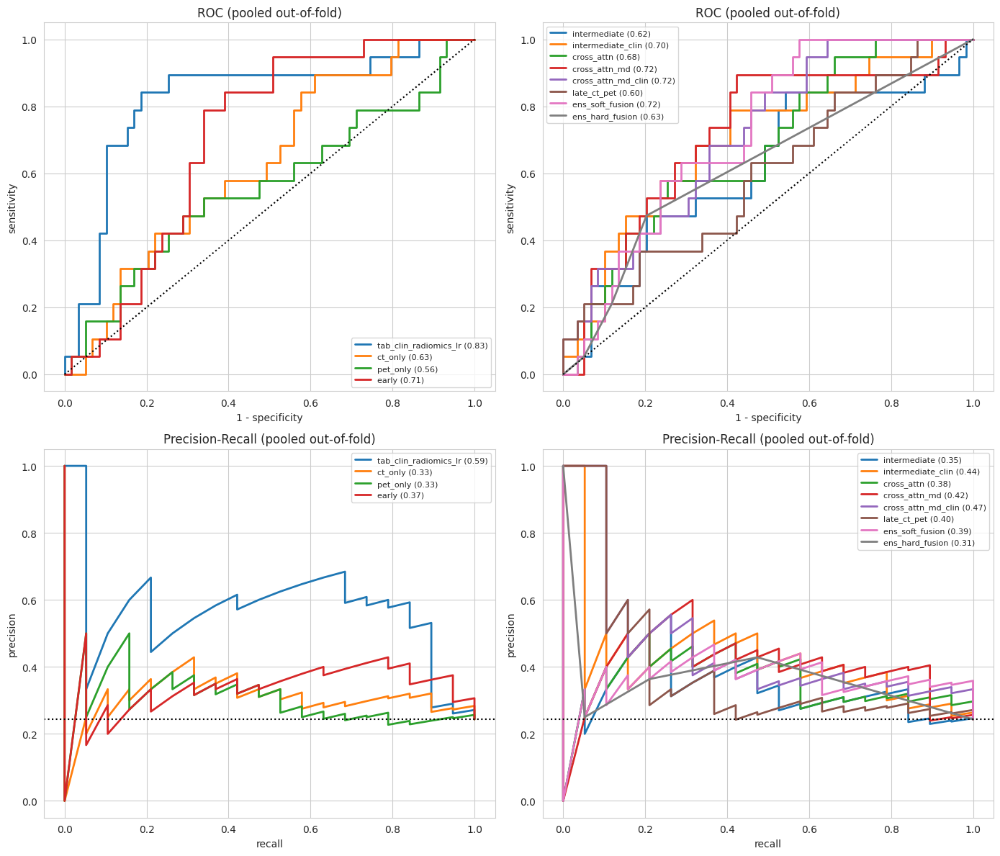

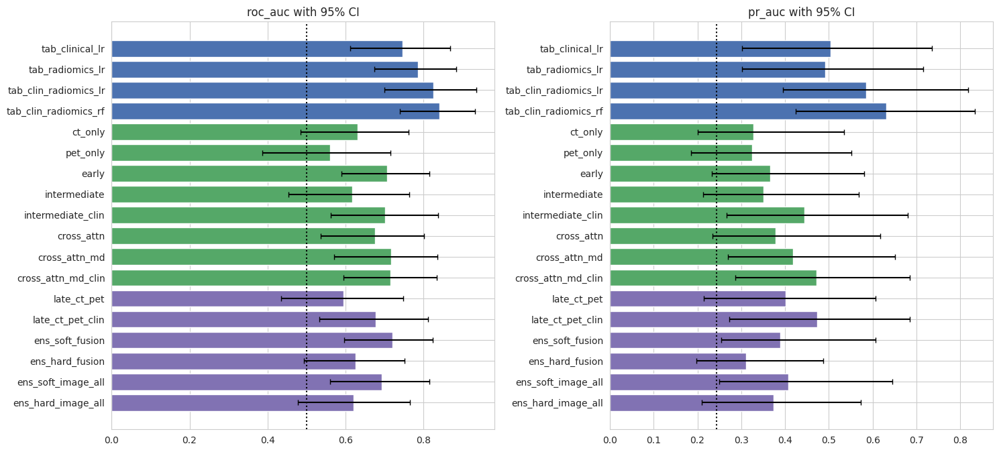

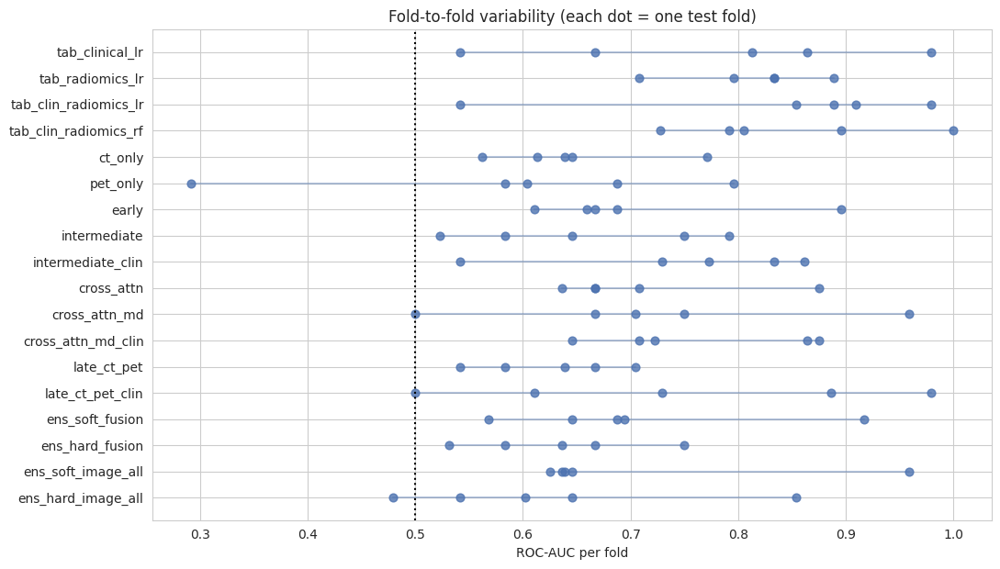

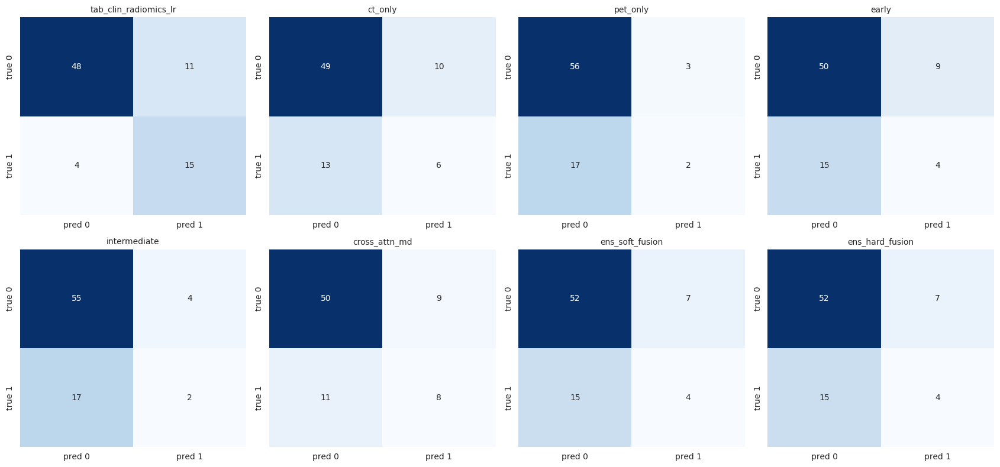

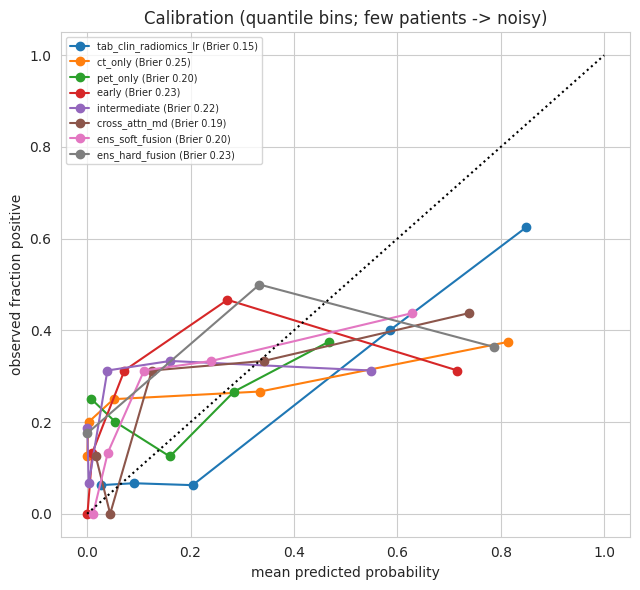

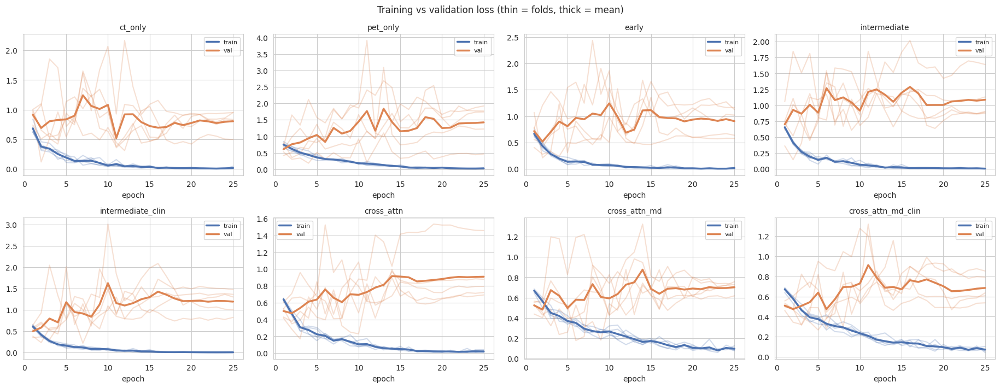


=== Ablation view (ROC-AUC [95% CI] | PR-AUC) ===

Modality (single vs both)
  tab_clin_radiomics_lr    0.825 [0.701, 0.937] | PR-AUC 0.586
  ct_only                  0.632 [0.486, 0.763] | PR-AUC 0.328
  pet_only                 0.560 [0.388, 0.715] | PR-AUC 0.325
  early                    0.707 [0.590, 0.816] | PR-AUC 0.365

Fusion strategy
  early                    0.707 [0.590, 0.816] | PR-AUC 0.365
  intermediate             0.617 [0.454, 0.764] | PR-AUC 0.351
  cross_attn               0.675 [0.536, 0.802] | PR-AUC 0.379
  late_ct_pet              0.596 [0.436, 0.749] | PR-AUC 0.401

Modality dropout (proposed)
  cross_attn               0.675 [0.536, 0.802] | PR-AUC 0.379
  cross_attn_md            0.718 [0.571, 0.836] | PR-AUC 0.419

Adding clinical features
  intermediate             0.617 [0.454, 0.764] | PR-AUC 0.351
  intermediate_clin        0.702 [0.563, 0.837] | PR-AUC 0.445
  cross_attn_md            0.718 [0.571, 0.836] | PR-AUC 0.419
  cross_attn_md_clin       0.71

In [20]:
# CELL 18 - full evaluation: tables, ROC / PR, CI bars, per-fold spread, confusion matrices, calibration, training curves
ORDER = [m for m in ["tab_clinical_lr", "tab_radiomics_lr", "tab_clin_radiomics_lr", "tab_clin_radiomics_rf",
                     "ct_only", "pet_only", "early", "intermediate", "intermediate_clin", "cross_attn", "cross_attn_md",
                     "cross_attn_md_clin", "late_ct_pet", "late_ct_pet_clin", "ens_soft_fusion", "ens_hard_fusion",
                     "ens_soft_image_all", "ens_hard_image_all"] if m in OOF]
RES = summarize_oof({m: OOF[m] for m in ORDER}, B=1000)
RES.to_csv(f"{RES_DIR}/results_all_models.csv")
show = RES[["roc_auc", "roc_auc_lo", "roc_auc_hi", "pr_auc", "balanced_acc", "sensitivity", "specificity", "f1", "brier"]].astype(float).round(3)
print("=== Pooled out-of-fold results (patient level; threshold 0.5; 95% CI by patient bootstrap) ===")
print(show.to_string())
prev = float(np.mean([LABELS[p] for p in PIDS]))
print(f"\nPositive-class prevalence = {prev:.3f}  (PR-AUC of a random classifier ~ {prev:.3f})")

GROUP_A = [m for m in ["tab_clin_radiomics_lr", "ct_only", "pet_only", "early"] if m in OOF]
GROUP_B = [m for m in ["intermediate", "intermediate_clin", "cross_attn", "cross_attn_md", "cross_attn_md_clin",
                       "late_ct_pet", "ens_soft_fusion", "ens_hard_fusion"] if m in OOF]
pal = sns.color_palette("tab10", 12)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for col, grp in enumerate((GROUP_A, GROUP_B)):
    for i, m in enumerate(grp):
        d = OOF[m]
        fpr, tpr, _ = roc_curve(d["label"], d["prob"]); axes[0, col].plot(fpr, tpr, lw=2, color=pal[i], label=f"{m} ({RES.loc[m, 'roc_auc']:.2f})")
        pr, rc, _ = precision_recall_curve(d["label"], d["prob"]); axes[1, col].plot(rc, pr, lw=2, color=pal[i], label=f"{m} ({RES.loc[m, 'pr_auc']:.2f})")
    axes[0, col].plot([0, 1], [0, 1], "k:"); axes[0, col].set_title("ROC (pooled out-of-fold)"); axes[0, col].set_xlabel("1 - specificity"); axes[0, col].set_ylabel("sensitivity")
    axes[1, col].axhline(prev, color="k", ls=":"); axes[1, col].set_title("Precision-Recall (pooled out-of-fold)"); axes[1, col].set_xlabel("recall"); axes[1, col].set_ylabel("precision")
    for r in (0, 1):
        axes[r, col].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval1_roc_pr.png", dpi=140); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, max(5, 0.38 * len(ORDER))))
for ax, (metric, lo, hi, base) in zip(axes, [("roc_auc", "roc_auc_lo", "roc_auc_hi", 0.5), ("pr_auc", "pr_auc_lo", "pr_auc_hi", prev)]):
    r = RES.loc[ORDER, [metric, lo, hi]].astype(float)
    y = np.arange(len(r))
    ax.barh(y, r[metric], xerr=[r[metric] - r[lo], r[hi] - r[metric]], color=["#8172B3" if m.startswith(("ens", "late")) else "#4C72B0" if m.startswith("tab") else "#55A868" for m in r.index], capsize=3)
    ax.set_yticks(y); ax.set_yticklabels(r.index); ax.invert_yaxis(); ax.axvline(base, color="k", ls=":"); ax.set_title(f"{metric} with 95% CI")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval2_auc_bars_ci.png", dpi=140); plt.show()

pf = pd.DataFrame({m: per_fold_auc(OOF[m]) for m in ORDER}).T
plt.figure(figsize=(11, max(4, 0.35 * len(ORDER))))
for i, m in enumerate(pf.index):
    plt.scatter(pf.loc[m].values, [i] * pf.shape[1], color="#4C72B0", s=40, alpha=0.8)
    plt.plot([np.nanmin(pf.loc[m]), np.nanmax(pf.loc[m])], [i, i], color="#4C72B0", alpha=0.4)
plt.yticks(range(len(pf)), pf.index); plt.gca().invert_yaxis(); plt.axvline(0.5, color="k", ls=":"); plt.xlabel("ROC-AUC per fold")
plt.title("Fold-to-fold variability (each dot = one test fold)"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval3_per_fold_auc.png", dpi=140); plt.show()

KEY = [m for m in ["tab_clin_radiomics_lr", "ct_only", "pet_only", "early", "intermediate", "cross_attn_md", "ens_soft_fusion", "ens_hard_fusion"] if m in OOF]
fig, axes = plt.subplots(2, 4, figsize=(17, 8)); axes = axes.ravel()
for ax, m in zip(axes, KEY):
    cm = confusion_matrix(OOF[m]["label"], (OOF[m]["prob"] >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"]); ax.set_title(m, fontsize=10)
for ax in axes[len(KEY):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval4_confusion_matrices.png", dpi=140); plt.show()

plt.figure(figsize=(6.5, 6))
for i, m in enumerate(KEY):
    try:
        fp, mp = calibration_curve(OOF[m]["label"], OOF[m]["prob"], n_bins=5, strategy="quantile")
        plt.plot(mp, fp, marker="o", color=pal[i], label=f"{m} (Brier {RES.loc[m, 'brier']:.2f})")
    except ValueError:
        pass
plt.plot([0, 1], [0, 1], "k:"); plt.xlabel("mean predicted probability"); plt.ylabel("observed fraction positive")
plt.title("Calibration (quantile bins; few patients -> noisy)"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eval5_calibration.png", dpi=140); plt.show()

hist_models = [m for m in ORDER if m in HIST]
if hist_models:
    nc = 4; nr = int(np.ceil(len(hist_models) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(4.6 * nc, 3.6 * nr), squeeze=False); axes = axes.ravel()
    for ax, m in zip(axes, hist_models):
        h = HIST[m]
        for _, g in h.groupby("fold"):
            ax.plot(g["epoch"], g["train_loss"], color="#4C72B0", alpha=0.25); ax.plot(g["epoch"], g["val_loss"], color="#DD8452", alpha=0.25)
        mm = h.groupby("epoch")[["train_loss", "val_loss"]].mean()
        ax.plot(mm.index, mm["train_loss"], color="#4C72B0", lw=2.5, label="train"); ax.plot(mm.index, mm["val_loss"], color="#DD8452", lw=2.5, label="val")
        ax.set_title(m, fontsize=10); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
    for ax in axes[len(hist_models):]:
        ax.axis("off")
    plt.suptitle("Training vs validation loss (thin = folds, thick = mean)"); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/eval6_training_curves.png", dpi=140); plt.show()

ABL = {"Modality (single vs both)": ["tab_clin_radiomics_lr", "ct_only", "pet_only", "early"],
       "Fusion strategy": ["early", "intermediate", "cross_attn", "late_ct_pet"],
       "Modality dropout (proposed)": ["cross_attn", "cross_attn_md"],
       "Adding clinical features": ["intermediate", "intermediate_clin", "cross_attn_md", "cross_attn_md_clin"],
       "Ensembles": ["ens_soft_fusion", "ens_hard_fusion", "ens_soft_image_all", "ens_hard_image_all"]}
print("\n=== Ablation view (ROC-AUC [95% CI] | PR-AUC) ===")
for title, ms in ABL.items():
    print(f"\n{title}")
    for m in [x for x in ms if x in RES.index]:
        r = RES.loc[m]
        print(f"  {m:24s} {r['roc_auc']:.3f} [{r['roc_auc_lo']:.3f}, {r['roc_auc_hi']:.3f}] | PR-AUC {r['pr_auc']:.3f}")

available           CT only (PET missing)  PET only (CT missing)   both
model                                                                  
cross_attn                          0.659                  0.648  0.675
cross_attn_md                       0.690                  0.624  0.718
cross_attn_md_clin                  0.666                  0.689  0.715
early                               0.690                  0.501  0.707
intermediate                        0.568                  0.608  0.617
intermediate_clin                   0.626                  0.726  0.702


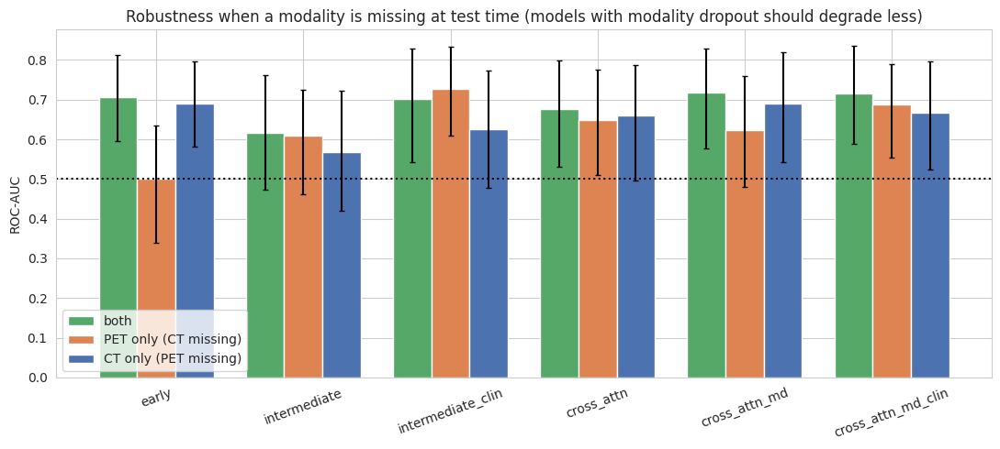

In [21]:
# CELL 19 - missing-modality robustness (same trained models, one modality blanked at test time)
if OOF_MISS:
    rows = []
    for m, d in OOF_MISS.items():
        full = OOF[m]
        for label_, df_ in [("both", full), ("PET only (CT missing)", d["ct"]), ("CT only (PET missing)", d["pet"])]:
            lo, hi = bootstrap_ci(df_["label"], df_["prob"], roc_auc_score, 500)
            rows.append({"model": m, "available": label_, "roc_auc": roc_auc_safe(df_["label"], df_["prob"]), "lo": lo, "hi": hi,
                         "balanced_acc": compute_metrics(df_["label"], df_["prob"])["balanced_acc"]})
    MISS = pd.DataFrame(rows)
    MISS.to_csv(f"{RES_DIR}/results_missing_modality.csv", index=False)
    print(MISS.pivot(index="model", columns="available", values="roc_auc").round(3).to_string())
    models_m = list(OOF_MISS.keys())
    fig, ax = plt.subplots(figsize=(11, 5)); w = 0.26
    for k, (lab, color) in enumerate([("both", "#55A868"), ("PET only (CT missing)", "#DD8452"), ("CT only (PET missing)", "#4C72B0")]):
        sub = MISS[MISS["available"] == lab].set_index("model").loc[models_m]
        ax.bar(np.arange(len(models_m)) + (k - 1) * w, sub["roc_auc"], w, yerr=[sub["roc_auc"] - sub["lo"], sub["hi"] - sub["roc_auc"]], capsize=2, label=lab, color=color)
    ax.axhline(0.5, color="k", ls=":"); ax.set_xticks(range(len(models_m))); ax.set_xticklabels(models_m, rotation=20); ax.set_ylabel("ROC-AUC"); ax.legend()
    ax.set_title("Robustness when a modality is missing at test time (models with modality dropout should degrade less)")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval7_missing_modality.png", dpi=140); plt.show()
else:
    print("No fusion model has been trained yet - run the fusion cells first.")

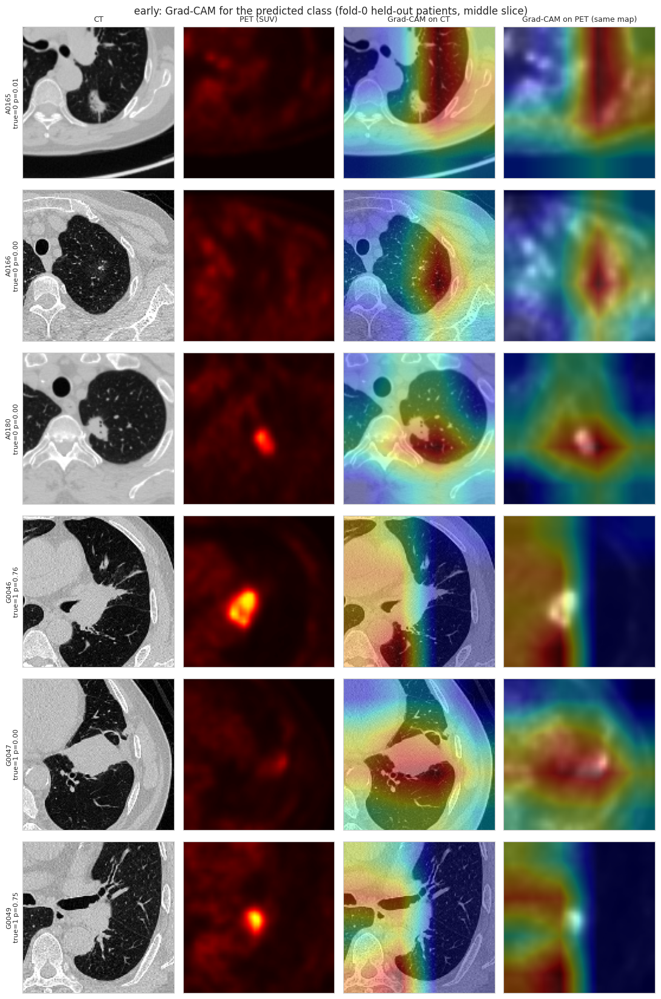

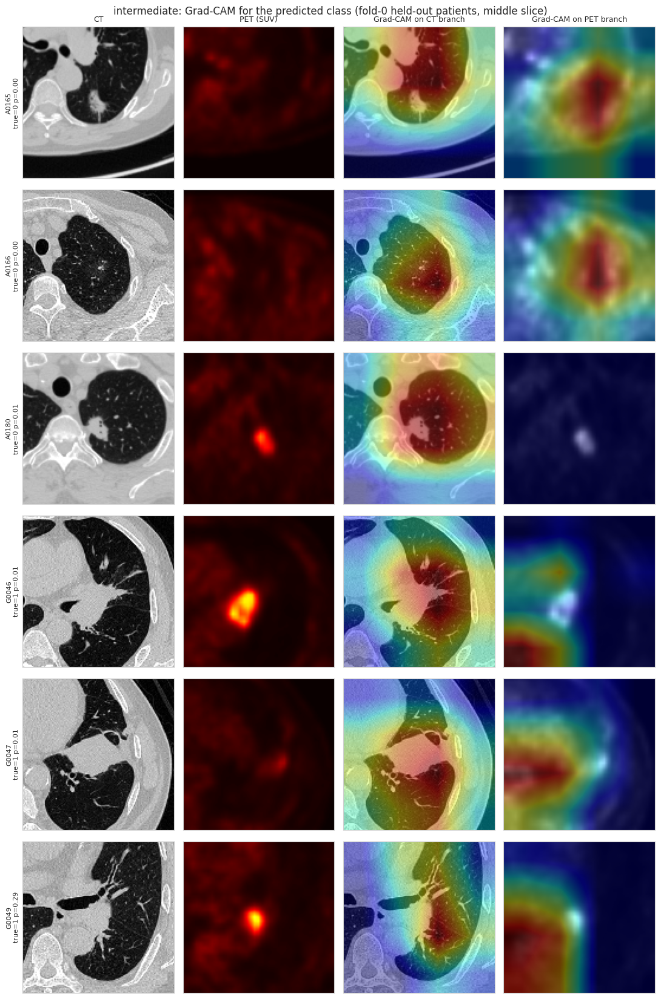

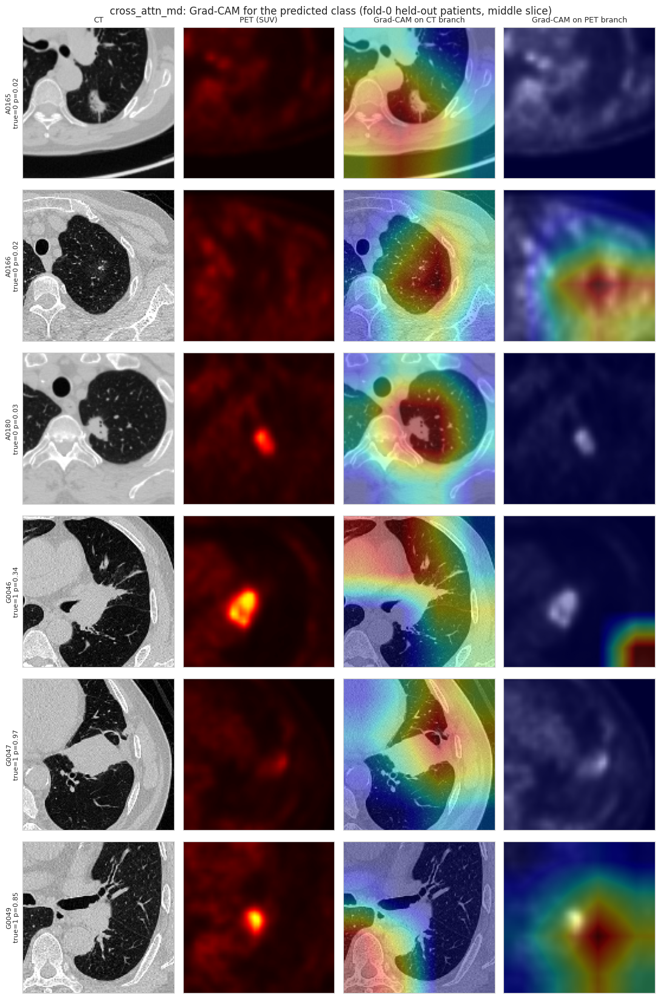

Mean learned modality weights by class (fold-0 held-out patients):
        w_CT  w_PET
label              
0      0.713  0.287
1      0.510  0.490


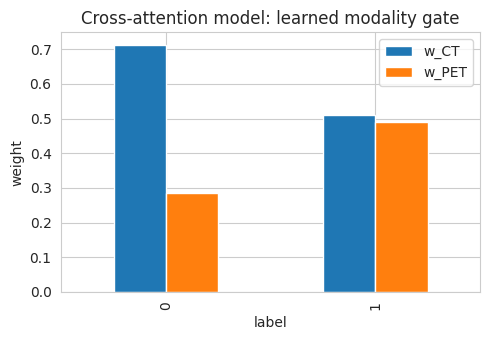

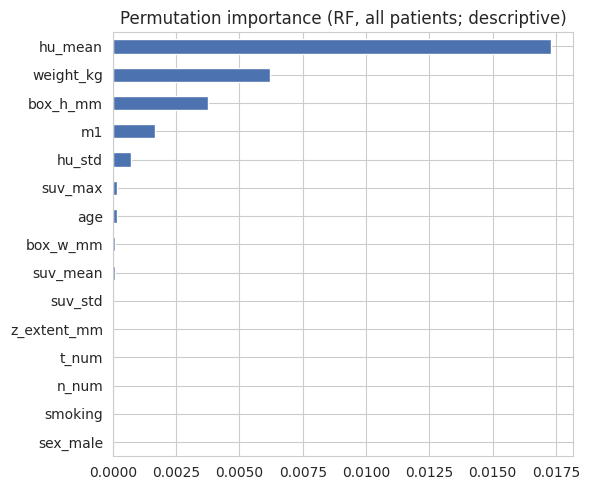

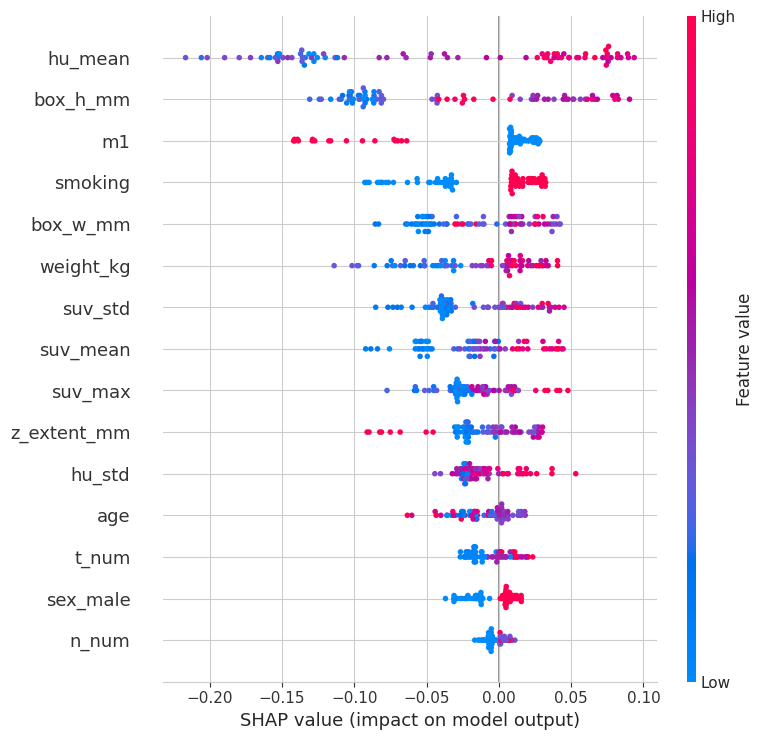

In [22]:
# CELL 20 - explainability: Grad-CAM, learned modality gate, tabular feature importance
def grad_cam(model, x, clin, layer, class_idx):
    store = {}

    def fwd_hook(module, inp, out):
        store["a"] = out
        out.register_hook(lambda g: store.__setitem__("g", g))

    handle = layer.register_forward_hook(fwd_hook)
    model.zero_grad()
    with torch.enable_grad():
        out = model(x, clin)
        out[0, class_idx].backward()
    handle.remove()
    cam = F.relu((store["g"].mean(dim=(2, 3), keepdim=True) * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min()
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()


def load_fold0(name):
    p = f"{WEIGHT_DIR}/{name}_fold0.pt"
    if not os.path.exists(p):
        return None
    model = build_model(name, 0).to(DEVICE)
    model.load_state_dict(torch.load(p, map_location=DEVICE)); model.eval()
    return model


fold0_test = [p for p in PIDS if FOLD_OF[p] == 0]
chosen = [p for lab in (0, 1) for p in [q for q in fold0_test if LABELS[q] == lab][:3]]
CAM_LAYERS = {"early": lambda m: (m.enc.layer4, m.enc.layer4),
              "intermediate": lambda m: (m.enc_ct.layer4, m.enc_pet.layer4),
              "cross_attn_md": lambda m: (m.enc_ct.layer4, m.enc_pet.layer4)}
for name, get_layers in CAM_LAYERS.items():
    model = load_fold0(name)
    if model is None or not chosen:
        print(f"Grad-CAM skipped for {name} (no fold-0 weights; train it first)"); continue
    fig, axes = plt.subplots(len(chosen), 4, figsize=(11, 2.8 * len(chosen))); axes = np.atleast_2d(axes)
    for i, pid in enumerate(chosen):
        ct, pet = CROPS[pid]; j = ct.shape[0] // 2
        x = torch.from_numpy(np.stack([ct[j], pet[j]])[None]).float().to(DEVICE)
        with torch.no_grad():
            prob = torch.softmax(model(x, None), 1)[0, 1].item()
        cls = int(prob >= 0.5)
        l_ct, l_pet = get_layers(model)
        cam_ct, cam_pet = grad_cam(model, x, None, l_ct, cls), grad_cam(model, x, None, l_pet, cls)
        axes[i, 0].imshow(ct[j], cmap="gray", vmin=0, vmax=1); axes[i, 1].imshow(pet[j] * PET_SUV_MAX, cmap="hot", vmin=0, vmax=PET_SUV_MAX)
        axes[i, 2].imshow(ct[j], cmap="gray", vmin=0, vmax=1); axes[i, 2].imshow(cam_ct, cmap="jet", alpha=0.4)
        axes[i, 3].imshow(pet[j] * PET_SUV_MAX, cmap="gray"); axes[i, 3].imshow(cam_pet, cmap="jet", alpha=0.4)
        axes[i, 0].set_ylabel(f"{pid}\ntrue={LABELS[pid]} p={prob:.2f}", fontsize=8)
        for a in axes[i]:
            a.set_xticks([]); a.set_yticks([])
    shared = l_ct is l_pet                                  # early fusion: one encoder sees both channels
    for a, t in zip(axes[0], ["CT", "PET (SUV)", "Grad-CAM on CT" if shared else "Grad-CAM on CT branch",
                              "Grad-CAM on PET (same map)" if shared else "Grad-CAM on PET branch"]):
        a.set_title(t, fontsize=9)
    plt.suptitle(f"{name}: Grad-CAM for the predicted class (fold-0 held-out patients, middle slice)"); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/explain_gradcam_{name}.png", dpi=140); plt.show()

gate_model = load_fold0("cross_attn_md")
if gate_model is not None:
    rows = []
    with torch.no_grad():
        for pid in fold0_test:
            ct, pet = CROPS[pid]
            gate_model(torch.from_numpy(np.stack([ct, pet], 1)).float().to(DEVICE), None)
            g = gate_model.last_gate.mean(0).cpu().numpy()
            rows.append({"patient_id": pid, "label": LABELS[pid], "w_CT": g[0], "w_PET": g[1]})
    G = pd.DataFrame(rows).groupby("label")[["w_CT", "w_PET"]].mean()
    print("Mean learned modality weights by class (fold-0 held-out patients):"); print(G.round(3).to_string())
    G.plot(kind="bar", figsize=(5, 3.5), title="Cross-attention model: learned modality gate"); plt.ylabel("weight"); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/explain_modality_gate.png", dpi=140); plt.show()

# Tabular importance (descriptive: model fit on all patients, NOT an evaluation)
cols = CLIN_COLS + RAD_COLS
Xt = pd.DataFrame(SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(MASTER.set_index("patient_id").loc[PIDS, cols]), columns=cols)
yt = np.array([LABELS[p] for p in PIDS])
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced_subsample", random_state=SEED).fit(Xt, yt)
from sklearn.inspection import permutation_importance
pi_ = permutation_importance(rf, Xt, yt, n_repeats=20, random_state=SEED, scoring="roc_auc")
imp = pd.Series(pi_.importances_mean, index=cols).sort_values()
plt.figure(figsize=(6, 5)); imp.plot(kind="barh", color="#4C72B0"); plt.title("Permutation importance (RF, all patients; descriptive)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/explain_tabular_importance.png", dpi=140); plt.show()
try:
    import shap
    sv = shap.TreeExplainer(rf).shap_values(Xt)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
    shap.summary_plot(sv, Xt, show=False); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/explain_tabular_shap.png", dpi=140, bbox_inches="tight"); plt.show()
except Exception as e:
    print("SHAP summary skipped:", type(e).__name__)

In [23]:
# CELL 21 - save run summary and zip results (volumes excluded: several GB, regenerable)
summary = {"task": TASK, "quick_test": QUICK_TEST, "n_patients": len(PIDS), "n_folds": N_FOLDS, "epochs": EPOCHS,
           "label_counts": {str(k): int(v) for k, v in MASTER["label"].value_counts().items()},
           "models_trained": [m for m in MODEL_SPECS if m in OOF], "crop_fov_mm": CROP_FOV_MM, "crop_px": CROP_PX,
           "slices_per_patient": SLICES_PER_PATIENT, "seed": SEED}
json.dump(summary, open(f"{RES_DIR}/run_summary.json", "w"), indent=2)

STAGE = "/kaggle/working/_zip_stage"
shutil.rmtree(STAGE, ignore_errors=True); os.makedirs(STAGE)
shutil.copytree(RES_DIR, f"{STAGE}/phase2_results", ignore=shutil.ignore_patterns("volumes", "*.nii.gz"))
shutil.copytree(FIG_DIR, f"{STAGE}/figures_phase2")
zp = shutil.make_archive("/kaggle/working/phase2_results_bundle", "zip", STAGE)
shutil.rmtree(STAGE)
print(f"Created {zp} ({os.path.getsize(zp) / 1e6:.0f} MB) - download it from the notebook's Output pane.")
if QUICK_TEST:
    print("\nQUICK_TEST run finished: these numbers only prove the pipeline works. Set QUICK_TEST = False and re-run for real results.")

Created /kaggle/working/phase2_results_bundle.zip (250 MB) - download it from the notebook's Output pane.
